# NLP1 · Project 1: Occupation classification on *Bias in Bios*

**Team:** Isha · Diya · Ioana  **Course:** NLP1, University of Amsterdam  **Week:** 1

**The task in one sentence.** Read a person's online bio and guess their **occupation** (one of 28), then
check whether the guesses are equally good for women and men.

We use `hard_text`: the bio *without* its first sentence, because that sentence names the job ("Anna is a
nurse"). Data: [`LabHC/bias_in_bios`](https://huggingface.co/datasets/LabHC/bias_in_bios) (De-Arteaga et al., 2019).
**Gender is never given to the model.** We only use it afterwards, to ask *for whom* each classifier works.

**Every system follows the same pipeline** (each box is one section of this notebook):

![pipeline](../figures/week1/diagrams/pipeline.png)

**What we compare: 3 ways to turn text into numbers × 3 kinds of model = 9 systems.**

| | A1 · log-linear | A2 · MLP (1 hidden layer) | A3 · deeper MLP *(ours)* |
|---|---|---|---|
| **R1** · token indicators (is the word there?) | `loglin_indicator` | `mlp_indicator` | `deep_indicator` |
| **R2** · bag-of-words (how often?) | `loglin_bow` | `mlp_bow` | `deep_bow` |
| **R3** · TF-IDF *(ours)* (how often, how rare?) | `loglin_tfidf` | `mlp_tfidf` | `deep_tfidf` |

**Notebook map:** 0 Setup · 1 Data · 2 Splits · 3 Tokenizer · 4 Representations · 5 Architectures ·
6 Metrics · 7 Cross-validation · 8 Results · 9 Bayesian comparison · 10 Fairness · 11 Extra: removing pronouns ·
12 Slide summary · 13 AI-assistance log

**Colours used throughout:** <span style="color:#eb6834">■ women</span> · <span style="color:#2a78d6">■ men</span> ·
<span style="color:#1baf7a">■ log-linear</span> · <span style="color:#6250d6">■ MLP</span> · <span style="color:#eda100">■ deeper MLP</span>

**How to read this notebook.** Every step has three parts: *what we do and why* → a short **code** cell
(with a grey "This cell" note above it) → *what we see / so what*.

## 0 · Setup

**Where the code lives.** Notebook cells stay short. The longer code lives in small files in `src/bib/`,
one per step. You can open any of them; each starts with a plain explanation.

| file | what it does, in one sentence |
|---|---|
| `bib/tokenizer.py` | learns the vocabulary of word pieces and cuts every bio into tokens (§3) |
| `bib/encoders.py` | turns token lists into the three kinds of number vectors R1–R3 (§4) |
| `bib/models.py` | the three models A1–A3, all with the same `fit` / `predict` buttons (§5) |
| `bib/tuning.py` | picks one setting per system before the real experiment (§5) |
| `bib/evaluation.py` | computes scores: macro-F1, accuracy, recall per gender (§6) |
| `bib/cv.py` | runs one system on every fold and saves the results (§7) |
| `bib/scrub.py` | deletes pronouns such as *he/she* from a bio (§11) |
| `bib/plots.py`, `bib/style.py` | all chart drawing, in one consistent style |
| `part1/…` | the course tutorial's code; we reuse some of it and never change it |

A **random seed** is the starting value of a random-number generator. Fixing it makes every shuffle and
every random starting point identical on each rerun, so anyone gets the same results.

> **This cell:** reload our `src/` files automatically when they change (handy while developing).

In [1]:
# [0a] reload src/ modules automatically when they change
%load_ext autoreload
%autoreload 2

> **This cell:** load the libraries we use, plus our own `bib` files and the tutorial's `part1` code.

In [2]:
# [0b] imports
import json, random, re, textwrap, time, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

from part1 import analysis                       # tutorial code (unchanged)
from bib import style, plots, encoders, models, evaluation, cv, tuning, scrub   # our code
from bib import tokenizer as btok

warnings.simplefilter("ignore", category=FutureWarning)
style.apply()                                    # one look for every figure
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.precision", 3)

> **This cell:** set the folders where results and figures are saved, fix the random seed, and tell torch to use the CPU with 8 threads.

In [3]:
# [0c] paths, seeds, device
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RESULTS = ROOT / "results" / "week1"    # saved tokenizer, splits, CV results (not in git: too big)
FIGURES = ROOT / "figures" / "week1"    # PNGs for slides and the blog (in git)
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

set_seed(0)
N_THREADS = 8                  # the M4 has 10 cores; sparse maths is not reliable on Apple's GPU, so CPU
torch.set_num_threads(N_THREADS)
print("project folder:", ROOT)

project folder: /Users/ishaparanjpe/UvA MSAI/NLP/NLP-Project/Bias-in-Bios/NLP1-Project


## 1 · Data & exploratory analysis

**Where the data comes from.** De-Arteaga et al. (2019) collected about 400k English bios from the web
(Common Crawl). A bio was kept if it started with *"[Name] is a(n) [occupation]"*, for one of 28
occupations. That occupation became the **label** (the answer we predict), and that sentence was then
**removed**.

**Gender** is binary and was **inferred from pronouns** (he/she). It is a *proxy* (an indirect stand-in),
not the person's own stated identity, and non-binary people are absent.

| Column | Meaning |
|---|---|
| `hard_text` | the bio without its first sentence |
| `profession` | occupation id 0–27 (the label) |
| `gender` | 0 = male, 1 = female (used for evaluation only) |

**Questions for this section:** How balanced are the occupations? How is gender spread across them?
What do bios look like? What does all that mean for how we measure and split?

### 1.1 Loading the data

> **This cell:** download the dataset once (it is cached afterwards) and turn each split into a table (a pandas DataFrame).

In [4]:
# [1.1a] load the three splits
raw = load_dataset("LabHC/bias_in_bios")
SPLITS = ["train", "dev", "test"]
dfs = {split: raw[split].to_pandas() for split in SPLITS}
print({s: len(d) for s, d in dfs.items()})

{'train': 257478, 'dev': 39642, 'test': 99069}


> **This cell:** give the occupation and gender codes readable names, and check that every code is one we expect.

In [5]:
# [1.1b] readable names (from the dataset card; profession is stored as a number)
PROFESSIONS = [
    "accountant", "architect", "attorney", "chiropractor", "comedian", "composer",
    "dentist", "dietitian", "dj", "filmmaker", "interior_designer", "journalist",
    "model", "nurse", "painter", "paralegal", "pastor", "personal_trainer",
    "photographer", "physician", "poet", "professor", "psychologist", "rapper",
    "software_engineer", "surgeon", "teacher", "yoga_teacher",
]
GENDERS = {0: "male", 1: "female"}
K = len(PROFESSIONS)   # number of classes = 28

for split, df in dfs.items():
    assert df["profession"].between(0, K - 1).all() and df["gender"].isin(GENDERS).all()
    df["profession_name"] = df["profession"].map(dict(enumerate(PROFESSIONS)))
    df["gender_name"] = df["gender"].map(GENDERS)

train_df, dev_df, test_df = dfs["train"], dfs["dev"], dfs["test"]
train_df.head(3)

,hard_text,profession,gender,profession_name,gender_name
0,"He is also the project lead of and major contributor to the open source assembler/simulator ""EASy68K."" He ...",21,0,professor,male
1,"She is able to assess, diagnose and treat minor illness conditions and exacerbations of some long term con...",13,1,nurse,female
2,"Prior to law school, Brittni graduated magna cum laude from DePaul University in 2011 with her Bachelor’s ...",2,1,attorney,female


### 1.2 Splits and data quality

We check the split sizes and three possible problems:
- **empty texts** (they would become all-zero vectors);
- **duplicates** in `train`. A copy in both the training and the validation part lets a model score points by
  *memorising*;
- **overlap** with `train`. The same bio in `dev`/`test` would **leak**: *leakage* means information from the data
  we evaluate on reaching the training, which makes scores look too good.

> **This cell:** count, for each split, the bios, occupations, % women, empty texts and duplicates.

In [6]:
# [1.2a] split overview
train_texts = set(train_df["hard_text"])
overview = pd.DataFrame({
    split: {"bios": len(df),
            "occupations present": df["profession"].nunique(),
            "% female": round(100 * df["gender"].mean(), 1),
            "empty texts": (df["hard_text"].str.strip() == "").sum(),
            "duplicate texts within split": df["hard_text"].duplicated().sum(),
            "texts also in train": df["hard_text"].isin(train_texts).sum() if split != "train" else 0}
    for split, df in dfs.items()}).T
overview

,bios,occupations present,% female,empty texts,duplicate texts within split,texts also in train
train,257478.0,28.0,46.1,0.0,382.0,0.0
dev,39642.0,28.0,46.1,0.0,18.0,95.0
test,99069.0,28.0,46.1,0.0,67.0,256.0


> **This cell:** find texts that appear more than once in `train`, and list the ones whose copies have *different* occupation labels.

In [7]:
# [1.2b] duplicated bios in train: which copies disagree on the label?
dups = train_df[train_df["hard_text"].duplicated(keep=False)]          # every row whose text occurs 2+ times
dup_groups = dups.groupby("hard_text").agg(
    copies=("profession", "size"),
    occupations=("profession_name", lambda s: ", ".join(sorted(set(s)))),
    n_occupations=("profession", "nunique"),
    n_genders=("gender", "nunique"))
conflicting = dup_groups[dup_groups["n_occupations"] > 1]

print(f"{len(dups):,} rows share their text with another row ({len(dup_groups):,} distinct texts)")
print(f"texts with conflicting occupation labels: {len(conflicting)} | conflicting gender: {(dup_groups['n_genders'] > 1).sum()}")
conflicting[["copies", "occupations"]].head(8)

676 rows share their text with another row (294 distinct texts)
texts with conflicting occupation labels: 15 | conflicting gender: 0


,copies,occupations
hard_text,,
"He is an in-network provider for Blue Cross Blue Shield EPO, Blue Cross Blue Shield Bronze, and Blue Cross Blue Shield HMO, as well as other insurance carriers.",6,"chiropractor, physician"
"He is an in-network provider for Blue Cross/Blue Shield, Blue Cross Blue Shield Bronze, and Blue Cross Blue Shield HMO, as well as other insurance carriers.",10,"dentist, physician, surgeon"
"He is an in-network provider for Blue Cross/Blue Shield, Blue Cross Blue Shield Bronze, and Blue Cross Blue Shield HMO, in addition to other insurance carriers.",7,"chiropractor, dentist"
"He is an in-network provider for Blue Cross/Blue Shield, Blue Cross Blue Shield EPO, and Blue Cross Blue Shield Bronze, as well as other insurance carriers.",6,"chiropractor, physician"
"He is an in-network provider for United Healthcare Compass, United Healthcare Navigate, and United Healthcare HSA, as well as other insurance carriers.",2,"chiropractor, surgeon"
"He is an in-network provider for several insurance carriers, including Blue Cross/Blue Shield, Blue Cross Blue Shield Bronze, and Blue Cross Blue Shield HMO.",7,"chiropractor, dentist"
"He is an in-network provider for several insurance carriers, including Blue Cross/Blue Shield, Blue Cross Blue Shield EPO, and Blue Cross Blue Shield Bronze.",5,"chiropractor, physician"
"He is in-network for Blue Cross Blue Shield EPO, Blue Cross Blue Shield Bronze, and Blue Cross Blue Shield HMO, in addition to other insurance carriers.",5,"chiropractor, physician"


**What we see (1.2)**
- **Splits:** 257,478 / 39,642 / 99,069 bios (65 / 10 / 25%). All 28 occupations are in every split, and every split
  is 46.1% female. **No empty bios.**
- **Duplicates are rare:** 382 extra copies in `train` (0.15%). But **15 duplicated texts carry different
  occupation labels**. They are directory boilerplate, e.g. *"He is an in-network provider for Blue Cross…"*,
  labelled dentist in one place and physician in another. That is **label noise**: the "right answer" itself
  is unreliable.
- **0 duplicates disagree on gender.** That fits gender being derived from the text (pronouns).
- 95 `dev` and 256 `test` bios also appear in `train` (≈0.25%).

**Why it matters → decision.** We **deduplicate before cross-validation (§2)**: we drop every copy of the 15
conflicting texts and keep one copy of every other duplicate.

### 1.3 What a bio looks like

> **This cell:** print four random bios in full, with their occupation and gender.

In [8]:
# [1.3a] four random training bios
for _, row in train_df.sample(4, random_state=1).iterrows():
    print(f"[{row['profession_name']} | {row['gender_name']}]")
    print(textwrap.fill(row["hard_text"], width=110), "\n")

[professor | female]
Previously, she was the Founder and Director of the Gender and Public Policy Program at the Dubai School of
Government and a Research Fellow at the Women and Public Policy Program, HKS, Harvard University. 

[professor | female]
Dr. Meter earned her BA degree in Psychology from The University of North Carolina at Asheville and her MS and
PhD degrees in Family Studies and Human Development from The University of Arizona where she was funded by a
National Science Foundation Graduate Research Fellowship. Prior to joining the faculty at USU, she worked as a
postdoctoral research associate at the University of Texas at Dallas. Diana’s primary research interest is
peer relations among children and adolescents. She teaches classes in research methods and human development.
Diana serves as a representative of the Society for Research in Child Development’s Student and Early Career
Council and the Society for Research on Adolescence’s Emerging Scholars Committee. Outside of

**What we see (1.3)**
- **Bios start mid-story** ("Previously, she was…"), because the first sentence was cut.
- **Gender cues are everywhere:** pronouns (*she, her*), first names (*Julia*), family words (*her husband David*).
  A model sees these like any other word. That's one way bias gets in.
- **Job words survive:** *primary care, clinical setting* (nurse); *Music Theory and Composition* (composer).
- **Jobs overlap:** the composer is also an *Assistant Professor*. Predicting "professor" would be counted wrong,
  but it's understandable.

### 1.4 How balanced are the occupations? And what does "doing nothing" score?

A **baseline** is a silly predictor that never reads the text. It shows the score you get for free; a real
model must beat it clearly.

> **This cell:** count how many bios each occupation has and draw it as bars.

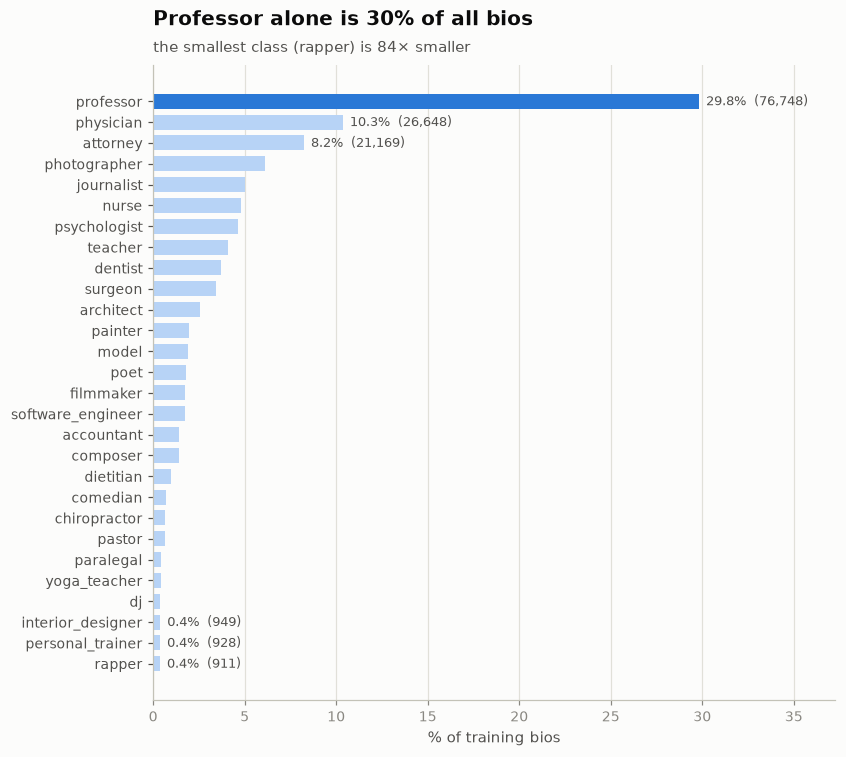

In [9]:
# [1.4a] class sizes
counts = train_df["profession_name"].value_counts()
fig = plots.class_shares(counts, f"Professor alone is {100 * counts.iloc[0] / counts.sum():.0f}% of all bios",
                         f"the smallest class ({counts.index[-1]}) is {counts.iloc[0] / counts.iloc[-1]:.0f}× smaller")
style.save(fig, FIGURES / "1_4_occupation_distribution.png"); plt.show()

> **This cell:** score two baselines that ignore the text: always say 'professor', and guess randomly in proportion to class sizes.

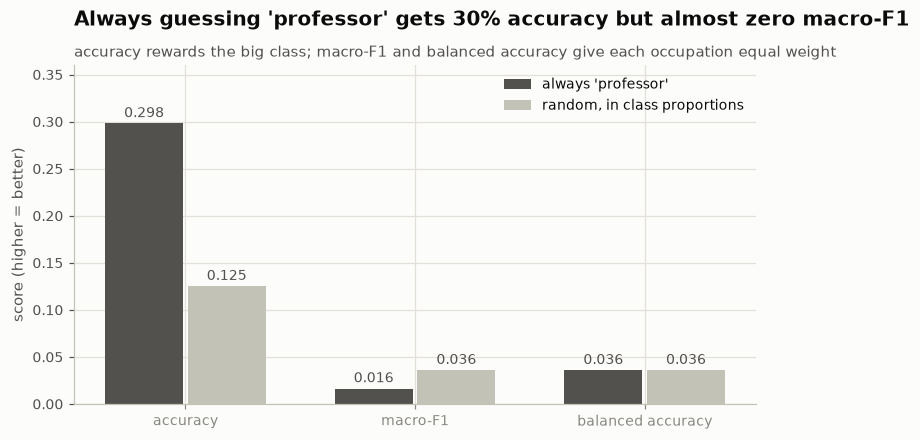

,accuracy,macro-F1,balanced accuracy
always 'professor',0.298,0.016,0.036
"random, in class proportions",0.125,0.036,0.036


In [10]:
# [1.4b] two "classifiers" that ignore the text
y = train_df["profession"].to_numpy()
always_professor = np.full_like(y, PROFESSIONS.index("professor"))
class_shares = np.bincount(y) / len(y)
random_guess = np.random.default_rng(0).choice(K, size=len(y), p=class_shares)

baseline_table = pd.DataFrame({
    name: {"accuracy": accuracy_score(y, pred),
           "macro-F1": f1_score(y, pred, average="macro", zero_division=0),
           "balanced accuracy": balanced_accuracy_score(y, pred)}
    for name, pred in [("always 'professor'", always_professor), ("random, in class proportions", random_guess)]}).T

fig = plots.baseline_bars(baseline_table, "Always guessing 'professor' gets 30% accuracy but almost zero macro-F1",
                          "accuracy rewards the big class; macro-F1 and balanced accuracy give each occupation equal weight")
style.save(fig, FIGURES / "1_4_baselines.png"); plt.show()
baseline_table

**Three scores in plain words** (all between 0 and 1, higher is better):
- **Accuracy:** the share of bios classified correctly. Big classes dominate it.
- **Precision and recall for one occupation**, say nurse. *Precision*: when the model says "nurse", how often is it
  right? *Recall*: of all real nurses, how many did it find? Recall is also called the **true positive rate (TPR)**.
- **F1** = 2·P·R / (P + R) combines the two. It is only high if both are high.
- **Macro-F1:** the plain average of the 28 per-occupation F1 scores, so rapper counts as much as professor.
- **Balanced accuracy:** the plain average of the 28 recalls.

**What we see (1.4)**
- **Strong imbalance.** Professor is 29.8% of bios (76,748), and the top three (professor, physician, attorney) are 48%.
  Six occupations are under 0.5% each (rapper 911 … paralegal 1,146). The biggest class is **84×** the smallest.
- **Accuracy is misleading here.** "Always professor" gets **0.298 accuracy** but **0.016 macro-F1**. Its balanced
  accuracy is 0.036 = 1/28: it finds every professor and nobody else.
- Random guessing gets 0.125 accuracy (= Σₖ pₖ², the chance two random labels agree) and 0.036 macro-F1.

**Decisions.** (1) **Macro-F1 is our main score**; we also report accuracy (to compare with papers) and balanced accuracy.
(2) **Stratified folds**, so every rare occupation appears in every fold in the same proportion. (3) A model has
learned something only if it clearly beats **0.30 accuracy / 0.04 macro-F1**.

### 1.5 Gender × occupation

If an occupation is mostly women in the training data, a model can learn *"female words → that occupation"*.
De-Arteaga et al. (2019) found that the gap between how well women and men are recognised in an occupation grows
with how imbalanced that occupation is: the model **amplifies** the imbalance it learned from.

> **This cell:** for every occupation, count women and men, and plot size against % women.

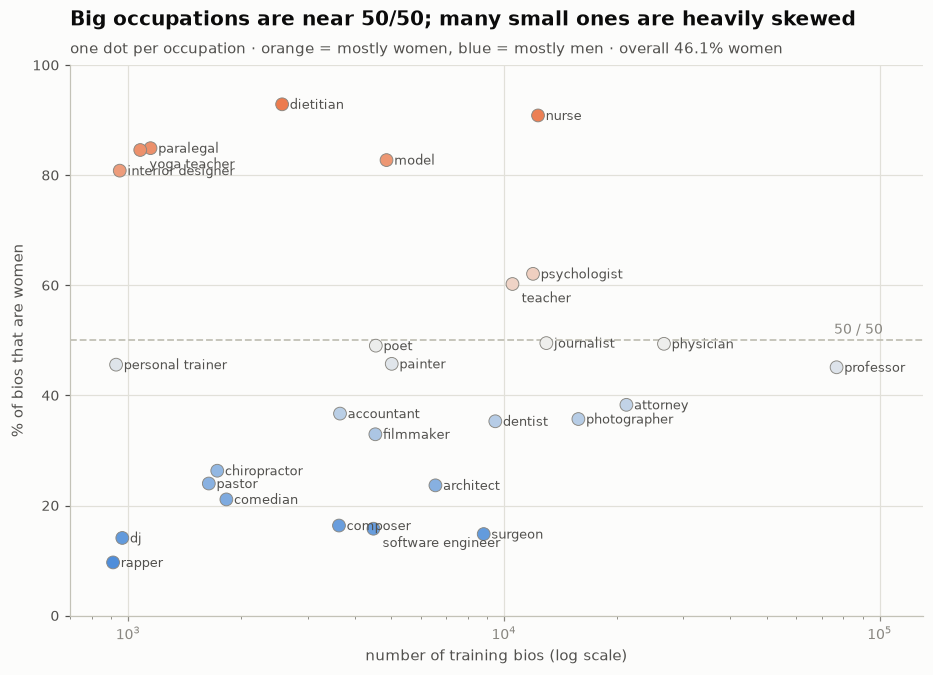

In [11]:
# [1.5a] size vs. gender share, one dot per occupation
gender_occ = pd.crosstab(train_df["profession_name"], train_df["gender_name"])
gender_occ["bios"] = gender_occ["female"] + gender_occ["male"]
gender_occ["% female"] = 100 * gender_occ["female"] / gender_occ["bios"]
gender_occ["smaller group"] = gender_occ[["female", "male"]].min(axis=1)

fig = plots.gender_scatter(gender_occ, "Big occupations are near 50/50; many small ones are heavily skewed",
                           f"one dot per occupation · orange = mostly women, blue = mostly men · overall {100 * train_df['gender'].mean():.1f}% women")
style.save(fig, FIGURES / "1_5_gender_by_occupation.png"); plt.show()

> **This cell:** list the occupations whose smaller gender group is tiniest (these are the hardest to measure fairly).

In [12]:
# [1.5b] the smallest gender groups
gender_occ.sort_values("smaller group")[["female", "male", "% female", "smaller group"]].head(8).round(1)

gender_name,female,male,% female,smaller group
profession_name,,,,
rapper,88,823,9.7,88
dj,136,828,14.1,136
yoga_teacher,910,166,84.6,166
paralegal,973,173,84.9,173
interior_designer,767,182,80.8,182
dietitian,2384,183,92.9,183
comedian,385,1439,21.1,385
pastor,393,1245,24.0,393


**What we see (1.5)**
- **Gender shares vary hugely:** from 9.7% women (rapper) to 92.9% (dietitian), around an overall 46.1%.
  - over 80% women: dietitian, nurse, paralegal, yoga teacher, model, interior designer;
  - under 25% women: rapper, DJ, surgeon, software engineer, composer, comedian, architect, pastor;
  - the three biggest classes are close to 50/50 (physician 49%, journalist 49%, professor 45%).
- **Smallest groups:** 88 female rappers, 136 female DJs, 166 male yoga teachers, 173 male paralegals.
- These shares describe **who has an English bio on the web**, not the real workforce.

**Why it matters → decision.** In an occupation that's 91% women, *"she"* becomes a clue for it, so a male nurse's
bio looks less nurse-like to the model. That's our **hypothesis for §10**. Tiny groups give noisy numbers, so for
fairness we **combine the predictions of all folds** before measuring (§6).

### 1.6 Bio length

Length matters for the representations. A longer bio switches on more words and has bigger counts. TF-IDF (R3)
removes length. If one gender wrote much longer bios, length could even become a hidden gender clue.

> **This cell:** count the words in every bio and summarise by gender and by occupation.

In [13]:
# [1.6a] length in words
train_df["n_words"] = train_df["hard_text"].str.split().str.len()
by_occ = train_df.groupby("profession_name")["n_words"].median().sort_values()
print("median words, all bios:", train_df["n_words"].median(), "| 5%–95%:", train_df["n_words"].quantile([.05, .95]).tolist())
print("median words by gender:", train_df.groupby("gender_name")["n_words"].median().to_dict())
print("shortest (median):", by_occ.head(3).to_dict(), "| longest:", by_occ.tail(3).to_dict())

median words, all bios: 55.0 | 5%–95%: [26.0, 116.0]
median words by gender: {'female': 55.0, 'male': 56.0}
shortest (median): {'model': 39.0, 'dentist': 42.0, 'chiropractor': 43.0} | longest: {'nurse': 60.0, 'composer': 61.0, 'professor': 65.0}


> **This cell:** draw the length distribution separately for women and men (as % of each group, so the bigger group doesn't look taller).

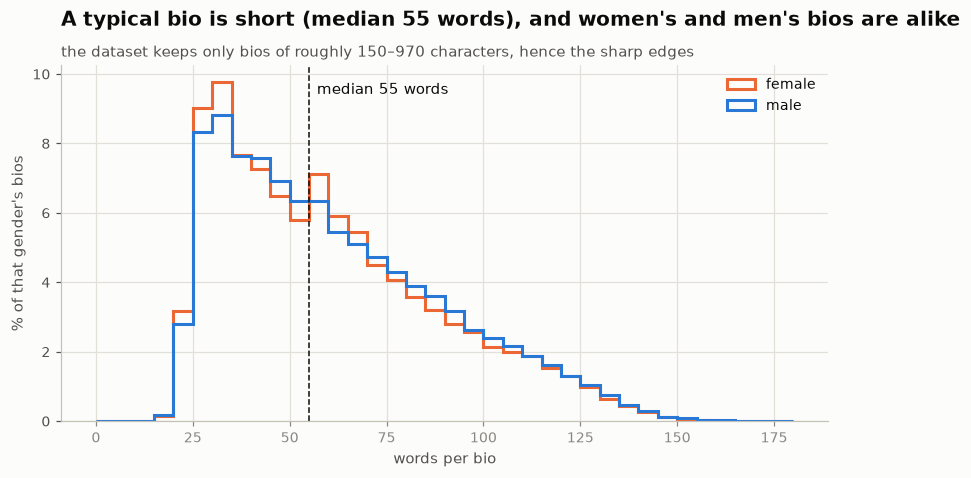

In [14]:
# [1.6b] length distribution, women vs men
med = train_df["n_words"].median()
fig = plots.length_hist(train_df["n_words"], train_df["gender_name"],
                        f"A typical bio is short (median {med:.0f} words), and women's and men's bios are alike",
                        "the dataset keeps only bios of roughly 150–970 characters, hence the sharp edges")
style.save(fig, FIGURES / "1_6_bio_length.png"); plt.show()

**What we see (1.6)**
- **Bios are short:** median **55 words** (5–95%: 26–116).
- **No gender difference:** median 55 words for women, 56 for men. Length is not a gender clue.
- **Some difference by occupation:** models (39), dentists (42) and chiropractors (43) write the shortest bios;
  nurses (60), composers (61) and professors (65) the longest.

**Why it matters → decision.** With raw counts (R2), a 116-word bio has about 4× the "weight" of a 26-word one,
even if both say the same about the job. TF-IDF (R3) scales every bio to the same size, so R2 vs R3 tests whether
that helps. We keep all bios as they are.

### 1.7 How much gender information is in the text?

Gender was *made from the pronouns*, and the pronouns are still in `hard_text`. So the model never gets gender
directly, but it may read it easily from the words. We test this with a one-line rule: guess *female* if
she/her/hers/herself occur more often than he/him/his/himself, *male* if the reverse.

> **This cell:** count female and male pronouns in every bio, apply the rule, and compare with the gender label.

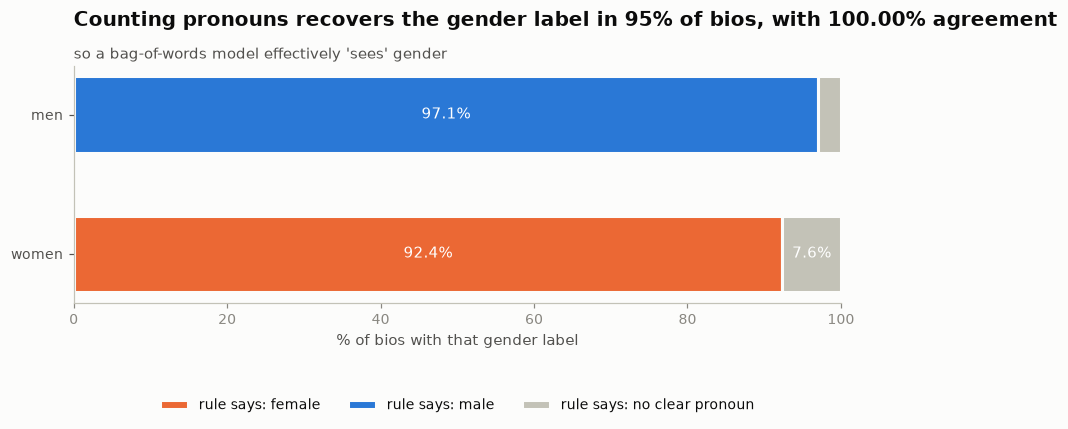

clear pronoun majority: 94.9% | agreement: 100.00% | median gendered pronouns per bio: 2


In [15]:
# [1.7a] a pronoun-counting "gender classifier"
lower = train_df["hard_text"].str.lower()
n_male = lower.str.count(r"\b(?:he|him|his|himself)\b")
n_female = lower.str.count(r"\b(?:she|her|hers|herself)\b")
train_df["pronoun_guess"] = np.select([n_female > n_male, n_male > n_female], ["female", "male"], default="no clear pronoun")

decided = train_df["pronoun_guess"] != "no clear pronoun"
agree = (train_df.loc[decided, "pronoun_guess"] == train_df.loc[decided, "gender_name"]).mean()
tab = 100 * pd.crosstab(train_df["gender_name"], train_df["pronoun_guess"], normalize="index")   # % of each row

fig = plots.pronoun_bars(tab, f"Counting pronouns recovers the gender label in {100 * decided.mean():.0f}% of bios, "
                              f"with {100 * agree:.2f}% agreement", "so a bag-of-words model effectively 'sees' gender")
style.save(fig, FIGURES / "1_7_pronoun_gender.png"); plt.show()
print(f"clear pronoun majority: {100 * decided.mean():.1f}% | agreement: {100 * agree:.2f}% | "
      f"median gendered pronouns per bio: {(n_male + n_female).median():.0f}")

> **This cell:** show three bios where the rule could not decide: what gender clues are left?

In [16]:
# [1.7b] bios without a clear pronoun
for _, row in train_df[~decided].sample(3, random_state=0).iterrows():
    print(f"[{row['profession_name']} | {row['gender_name']}]")
    print(textwrap.fill(row["hard_text"], width=110), "\n")

[physician | female]
Ms. Linehan practices medicine in Dublin, OH and specializes in Orthopaedic Surgery. Ms. Linehan is affiliated
with Dublin Methodist Hospital and Riverside Methodist Hospital. 

[physician | male]
Mr. Hudson practices medicine in Greensboro, NC and specializes in Family Medicine. Mr. Hudson is affiliated
with Wesley Long Hospital and Cone Health. Mr. Hudson speaks English and Spanish. 

[psychologist | female]
Dr. Mosley specializes in the treatment of health mental problems, and helps people to cope with their mental
illnesses. As a psychologist, Dr. Mosley evaluates and treats patients through a variety of methods, most
typically being psychotherapy or talk therapy. Patients usually visit Dr. Mosley because they have been
experiencing depression, anxiety, stress or anger for a significant period of time and are seeking help.
Psychologists may perform a variety of exams and assessments to diagnose a mental condition. 



**What we see (1.7)**
- **94.9%** of bios have a clear pronoun majority (median: 2 gendered pronouns per bio). In those, the rule matches the
  label in **100.00%** of cases, which is no surprise because the label *was made from* the pronouns.
- The other 5% (7.6% of women's bios, 2.9% of men's) mostly use **titles and names**: *Ms. Linehan*, *Mr. Hudson*,
  *Dr. Mosley* (that one has no clue at all).

**Why it matters → decision.** "Gender is not an input" is only true on paper: any bag-of-words model can read gender
from *she / he / her / his*. So we **measure** whether models use it (§10), and in §11 we test what happens when we
**delete** pronouns and titles.

### 1.8 Templates and noise

Many bios come from directory websites that fill one fixed template with different names. Such bios contain little
real information, and one template can be used for several occupations. Web noise (URLs, e-mails, phone numbers)
wastes vocabulary.

> **This cell:** find bios that start with exactly the same 60 characters as another bio (a sign of a shared template).

In [17]:
# [1.8a] near-duplicates: same first 60 characters
prefix = train_df["hard_text"].str[:60]
shared = prefix.duplicated(keep=False)
print(f"bios sharing their first 60 characters with another bio: {shared.sum():,} ({100 * shared.mean():.1f}%)")
templates = train_df[shared].groupby(prefix[shared]).agg(
    bios=("profession", "size"), occupations=("profession", "nunique"),
    most_common=("profession_name", lambda s: s.value_counts().index[0]))
templates.sort_values("bios", ascending=False).head(8)

bios sharing their first 60 characters with another bio: 17,495 (6.8%)


,bios,occupations,most_common
hard_text,,,
She graduated with honors in 2013. Having more than 3 years,293,3,nurse
She graduated with honors in 2012. Having more than 4 years,284,4,nurse
She graduated with honors in 2011. Having more than 5 years,255,3,nurse
She graduated with honors in 2009. Having more than 7 years,198,4,nurse
She graduated with honors in 2010. Having more than 6 years,197,4,nurse
"He practices in Anchorage, Alaska and has the professional c",186,3,physician
She graduated with honors in 2007. Having more than 10 years,177,4,nurse
She graduated with honors in 2008. Having more than 8 years,161,4,nurse


> **This cell:** measure how many bios contain each kind of web noise, and which special characters are most common.

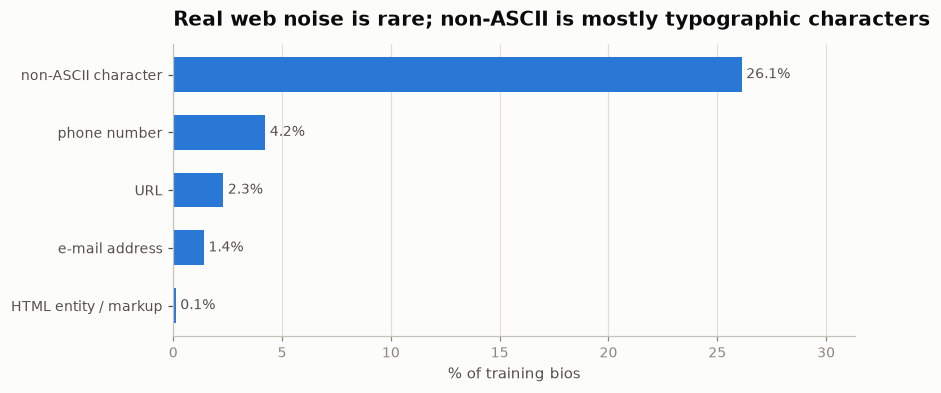

most common non-ASCII characters: [('’', 69040), ('”', 15294), ('“', 15079), ('–', 6224), ('é', 4054), ('‘', 3752), ('—', 2827), ('…', 2629)]


In [18]:
# [1.8b] web noise
noise_patterns = {
    "non-ASCII character":  r"[^\x00-\x7f]",
    "phone number":         r"\(?\d{3}\)?[-.\s]\d{3}[-.\s]\d{4}",
    "URL":                  r"https?://|www\.",
    "e-mail address":       r"\b[\w.+-]+@[\w-]+\.[\w.]+\b",
    "HTML entity / markup": r"&(?:amp|nbsp|quot|lt|gt);|<[a-z/][^>]*>",
}
noise = pd.Series({name: 100 * train_df["hard_text"].str.contains(p, regex=True).mean() for name, p in noise_patterns.items()})
fig = plots.hbars(noise, "Real web noise is rare; non-ASCII is mostly typographic characters", xlabel="% of training bios")
plt.show()
print("most common non-ASCII characters:", Counter(ch for t in train_df["hard_text"] for ch in t if ord(ch) > 127).most_common(8))

**What we see (1.8)**
- **Templates are common:** 17,495 bios (**6.8%**) open with exactly the same 60 characters as another bio.
- The biggest family is a healthcare-listing template, *"She graduated with honors in 20XX. Having more than N years…"*.
  It is mostly **nurse**, but each variant spans 2–4 occupations. A physician-directory template (*"He practices in
  Anchorage, Alaska…"*, 186 bios) spans 3.
- **Real noise is rare:** phone numbers 4.2%, URLs 2.3%, e-mails 1.4%, HTML 0.1%. "Non-ASCII" (26.1%) is almost all
  typography: curly quotes ’ “ ”, dashes – —, accented letters (é).

**Why it matters → decision.** **No cleaning:** noise is rare, and the tokenizer just turns it into a few extra
tokens. Templates stay (they are real data), but expect some "easy" classes to be easy because of template wording,
and confusions between medical jobs that share templates.

### 1.9 How much does a single keyword give away?

The first sentence ("X is a nurse") was removed, but the job word can still appear later. For each occupation we
search for its own word and close variants (*nurse / nurses / nursing*) and measure:
- **coverage:** % of that occupation's bios that contain the keyword (how *often* the clue is there);
- **reliability:** % of bios containing the keyword that really are that occupation (how far the clue can be *trusted*).

> **This cell:** search every bio for each occupation's keyword and compute coverage and reliability.

In [19]:
# [1.9a] keyword probe: one search pattern per occupation (on lowercased text)
KEYWORDS = {
    "accountant": r"\baccount(?:ant|ants|ing|ancy)\b", "architect": r"\barchitect", "attorney": r"\battorney",
    "chiropractor": r"\bchiropract", "comedian": r"\bcomed(?:ian|ians|y|ic)\b", "composer": r"\bcompos(?:er|ers|ition|itions)\b",
    "dentist": r"\bdent(?:ist|ists|istry|al)\b", "dietitian": r"\bdiet(?:itian|ician|etic|etics)", "dj": r"\bdjs?\b",
    "filmmaker": r"\bfilm", "interior_designer": r"\binterior design", "journalist": r"\bjournalis[mt]",
    "model": r"\bmodel(?:s|ing|ed)?\b", "nurse": r"\bnurs(?:e|es|ing)\b", "painter": r"\bpaint(?:er|ers|ing|ings)\b",
    "paralegal": r"\bparalegal", "pastor": r"\bpastor", "personal_trainer": r"\bpersonal train",
    "photographer": r"\bphotograph", "physician": r"\bphysician", "poet": r"\bpoe(?:t|ts|try|m|ms)\b",
    "professor": r"\bprofessor", "psychologist": r"\bpsycholog", "rapper": r"\brap(?:per|pers|ping)?\b|\bhip[- ]hop",
    "software_engineer": r"\bsoftware", "surgeon": r"\bsurg(?:eon|eons|ery|ical)\b",
    "teacher": r"\bteach(?:er|ers|ing)\b", "yoga_teacher": r"\byoga\b",
}
rows = []
for occ, pattern in KEYWORDS.items():
    has_keyword = lower.str.contains(pattern, regex=True)
    is_occ = train_df["profession_name"] == occ
    rows.append({"occupation": occ,
                 "coverage (%)": 100 * has_keyword[is_occ].mean(),       # of this occupation's bios, how many have it
                 "reliability (%)": 100 * is_occ[has_keyword].mean()})   # of bios with it, how many are this occupation
keyword_probe = pd.DataFrame(rows).set_index("occupation").round(1)

> **This cell:** plot coverage against reliability; the four corners tell four different stories.

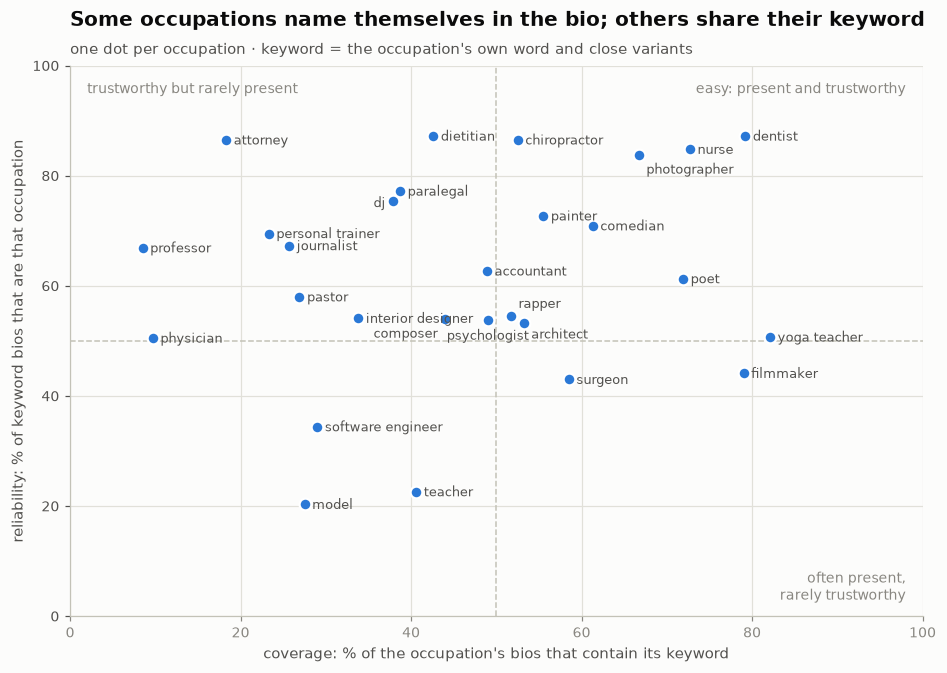

In [20]:
# [1.9b] coverage vs reliability
fig = plots.keyword_scatter(keyword_probe, "Some occupations name themselves in the bio; others share their keyword",
                            "one dot per occupation · keyword = the occupation's own word and close variants")
style.save(fig, FIGURES / "1_9_keyword_probe.png"); plt.show()

**What we see (1.9)**
- **Name themselves (top right):** dentist (coverage 79%, reliability 87%), nurse (73 / 85), photographer (67 / 84),
  chiropractor (53 / 87), painter (56 / 73), comedian (61 / 71), poet (72 / 61).
- **Trustworthy but rarely present (top left):** attorney (only 18% of attorney bios say "attorney", but 87% of the bios
  that do are attorneys), dietitian (43 / 87), paralegal, DJ, professor (8.5 / 67).
- **Shared keywords (bottom):** *model* (reliability 20%: "role model", "business model"), *teacher* (23%: everyone
  teaches), *software* (34%), *surgeon/surgery* (43%: physicians mention surgery too), *film* (44%), *physician* (50%).

**Prediction for §8.** High scores for the self-naming group. Low scores and many mix-ups for model, teacher, software
engineer, surgeon and physician.

### 1.10 From data to design decisions

| What we found | What we decided |
|---|---|
| 84× class imbalance; "always professor" = 29.8% accuracy | **macro-F1** as main score; accuracy and balanced accuracy too |
| rare occupations and small gender groups (down to 88) | **stratified folds**; fairness measured on all folds' predictions combined |
| duplicates, 15 with conflicting labels | **deduplicate** before cross-validation |
| pronouns reveal gender in 95% of bios | measure **recall gaps between women and men** (§10); test deleting pronouns (§11) |
| strong gender skew per occupation | hypothesis: bigger skew → bigger gap (De-Arteaga et al., 2019) |
| bio length varies 3–4× | motivates a **length-normalised representation (TF-IDF)** |
| big in-domain corpus (257k bios) | train **our own tokenizer** on these bios instead of the tutorial's news one |

### 1.11 Glossary

| Term | Meaning |
|---|---|
| **label / class** | the thing we predict: one of 28 occupations |
| **feature** | one number describing the input, e.g. "does the word *nurse* occur?" |
| **precision / recall (TPR)** | when we say *y*, how often are we right? / of all real *y*, how many did we find? |
| **F1, macro-F1** | combines precision and recall / plain average of F1 over all classes |
| **balanced accuracy** | plain average of recall over all classes |
| **baseline** | a trivial predictor that sets the floor (e.g. always "professor") |
| **stratification** | splitting so that each part has the same class (and gender) proportions |
| **cross-validation (CV)** | cut the data into *k* parts; train on *k−1*, test on the remaining one; repeat *k* times |
| **fold** | one of the *k* parts (or one train/test round) |
| **seed** | the starting value of a random generator; a different seed gives a different (but repeatable) shuffle |
| **leakage** | information from the evaluation data reaching training, which makes scores look too good |
| **label noise** | training labels that are wrong or ambiguous |
| **token / BPE** | a unit of text the model sees / the algorithm that learns those units (§3) |
| **overfitting** | memorising the training data instead of learning patterns that generalise |
| **hyperparameter** | a setting we choose before training (e.g. learning rate), as opposed to weights the model learns |
| **TPR gap** | recall for women minus recall for men, within one occupation (§6) |
| **posterior / ROPE** | what we believe about a difference after seeing the data / the range of "too small to matter" (§9) |

## 2 · Experimental splits

**The idea of cross-validation in plain words.** We want to know how well each system works on bios it has *never
seen*. So we hide part of the data, train on the rest, and test on the hidden part. With **3-fold** cross-validation
we cut the data into 3 equal parts and do this 3 times, hiding a different part each time. Every bio is tested once.
We then reshuffle with a second **seed** and repeat, giving **6 scores per system**.

![cv folds](../figures/week1/diagrams/cv_folds.png)

**Why these choices**
- **Cross-validation only inside `train`.** `dev` and `test` stay untouched this week, so `test` remains an honest
  final check for later projects and the blog.
- **3 folds × 2 seeds = 6 scores per system** (we first planned 5 × 3 = 15). Why fewer:
  - **Time.** The full 5 × 3 grid needed ≈ 1.5 hours; 3 × 2 needs ≈ 30 minutes.
  - **Each fold still trains on 171k bios** (2/3 of the data) and tests on 86k, which is plenty for stable scores.
  - **The cost:** 6 scores instead of 15 means more uncertainty in §9. The Bayesian test also *knows* that fold
    scores share training data, and with 3 folds it widens its uncertainty more than with 5 (it multiplies the
    variance by 1/6 + 1/2 ≈ 0.67, against 1/15 + 1/4 ≈ 0.32). So it will only call a difference "real" if it is
    clearly bigger than the noise. That's the honest price of a cheaper experiment.
  - **Why not 1 seed?** That would give only 3 scores, too few to say anything with confidence.
- **Deduplicated** (see 1.2), and **stratified by occupation × gender (56 groups)**: every part gets the same mix of
  occupations *and* the same share of women inside each occupation.
- **All 257k bios, no subsample.** Training one fold takes about a minute, so there's no reason to throw data away.
- **Saved to disk** (`results/week1/splits.json`), so everyone can recreate exactly the same folds.

> **This cell:** set the experiment size: number of folds, the seeds, and whether to use a subsample.

In [21]:
# [2a] experiment configuration
N_FOLDS   = 3            # k in k-fold cross-validation
SEEDS     = [0, 1]       # two different shuffles -> 3 x 2 = 6 scores per system
POOL_SIZE = None         # None = all deduplicated train bios

> **This cell:** remove duplicates, then cut the bios into 3 stratified folds, twice (once per seed), and save the result.

In [22]:
# [2b] build the CV pool and the folds
from sklearn.model_selection import StratifiedKFold

# 1) deduplicate: drop texts with conflicting labels completely, keep one copy of every other duplicate
dedup = train_df[~train_df["hard_text"].isin(conflicting.index)].drop_duplicates("hard_text")
pool = dedup[["hard_text", "profession", "gender"]].rename_axis("train_row").reset_index()
if POOL_SIZE:
    pool = pool.sample(POOL_SIZE, random_state=0).reset_index(drop=True)   # (not stratified; only for quick tests)
print(f"train: {len(train_df):,} bios -> after deduplication: {len(pool):,}")

# 2) the three things every later step needs
TEXTS = pool["hard_text"].tolist()      # the bios
Y = pool["profession"].to_numpy()       # the answers (occupation ids)
G = pool["gender"].to_numpy()           # gender, only for fairness analysis
STRATA = Y * 2 + G                      # 56 groups: (occupation, gender) -> stratify on these

# 3) folds: FOLDS[seed] = list of (train_rows, validation_rows), one pair per fold
FOLDS = {}
for seed in SEEDS:
    splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    FOLDS[seed] = list(splitter.split(TEXTS, STRATA))

# 4) save, so the exact same folds can be rebuilt later (bib.data.load_pool reads this file)
splits = {"pool_train_rows": pool["train_row"].tolist(),
          "val_folds": {str(s): [val.tolist() for _, val in FOLDS[s]] for s in SEEDS}}
(RESULTS / "splits.json").write_text(json.dumps(splits));

train: 257,478 bios -> after deduplication: 257,081


> **This cell:** check that the folds are fair copies of each other: same size, same % women, same smallest group.

In [23]:
# [2c] check the folds
rows = []
for seed in SEEDS:
    for f, (train_rows, val_rows) in enumerate(FOLDS[seed]):
        rows.append({"seed": seed, "fold": f, "train bios": len(train_rows), "validation bios": len(val_rows),
                     "% women (validation)": round(100 * G[val_rows].mean(), 2),
                     "smallest occupation×gender group (validation)": np.bincount(STRATA[val_rows], minlength=56).min()})
pd.DataFrame(rows)

,seed,fold,train bios,validation bios,% women (validation),smallest occupation×gender group (validation)
0,0,0,171387,85694,46.12,29
1,0,1,171387,85694,46.11,30
2,0,2,171388,85693,46.11,29
3,1,0,171387,85694,46.12,29
4,1,1,171387,85694,46.11,30
5,1,2,171388,85693,46.11,29


**What we see (2)**
- **Deduplication:** 257,478 → **257,081** bios (397 removed: the 382 extra copies, plus the last copy of each of the
  15 conflicting texts).
- **6 splits** (2 seeds × 3 folds). Each trains on 171,387–171,388 bios and validates on 85,693–85,694.
- **Stratification works:** every validation part is 46.11–46.12% women.
- The **smallest occupation × gender group per validation part** is 29–30 (female rappers). Small, which is why
  fairness uses the combined predictions (§6), where the group has all 88.

**So what.** All 9 systems are trained and tested on exactly these 6 splits (saved in `splits.json`), so §9 can
compare them split by split.

## 3 · Tokenizer

A model can't read a string. First the text must be cut into **tokens**: small units, each with a number. We use
**BPE (byte-pair encoding)**, as in the tutorial (Sennrich et al., 2016). It *learns* the units from data:
1. start with single characters;
2. find the pair of neighbouring units that occurs most often in all bios, and glue it into a new unit
   (`n`+`u` → `nu`, … later `nur`+`se` → `nurse`);
3. repeat until there are `VOCAB_SIZE` units. Only pairs seen at least `MIN_FREQ` times get glued.

**Result:** common words become one token; rare words (names, places, typos) are split into pieces instead of
becoming "unknown".

**Our choices, and why**
- **Learned from our own bios** (all 257k), not the tutorial's news articles. Job words like *chiropractic* or
  *paralegal* should be whole tokens.
- **No leakage of answers.** BPE only sees raw text, never occupations or gender, and all 9 systems share it.
- **Two changes to the tutorial's tokenizer:**
  1. **lowercase everything:** *He/he* and *Professor/professor* become one token;
  2. **cut punctuation off:** otherwise *"engineer."* and *"engineer"* would be different tokens.
- **10,000 tokens, glue only pairs seen ≥ 5 times.** Big enough to keep job words whole, small enough to keep the
  models small.

> **This cell:** learn the tokenizer from all bios (≈ 5 seconds), or load it if it was saved before.

In [24]:
# [3a] train (or load) our BPE tokenizer
VOCAB_SIZE, MIN_FREQ = 10_000, 5
TOKENIZER_PATH = RESULTS / f"bpe_lower_punct_v{VOCAB_SIZE}_mf{MIN_FREQ}.json"
tokenizer = btok.load_or_train(TOKENIZER_PATH, TEXTS, VOCAB_SIZE, MIN_FREQ)
V = tokenizer.get_vocab_size()
print(f"vocabulary: {V:,} tokens")

vocabulary: 10,000 tokens


> **This cell:** cut one example sentence with the tutorial's tokenizer and with ours, and draw both.

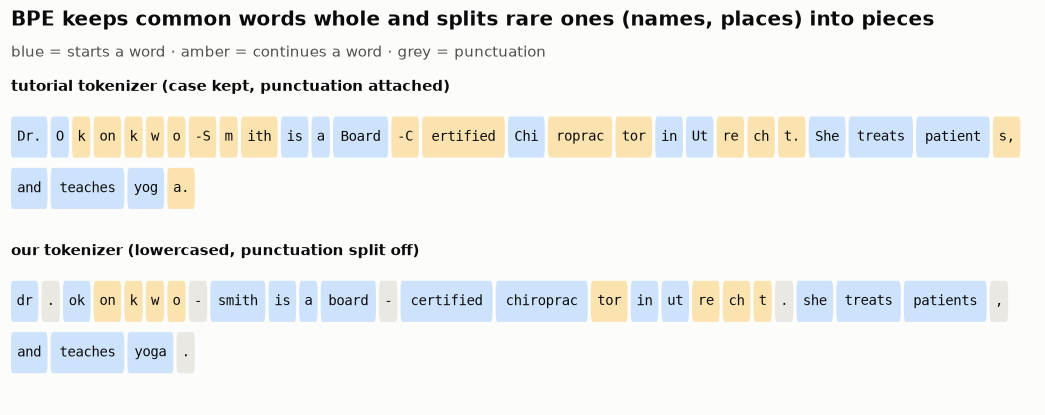

In [25]:
# [3b] tutorial-style tokenizer vs ours, on the same sentence
from part1.experiment import train_tokenizer as tutorial_train_tokenizer
tutorial_tok = tutorial_train_tokenizer(TEXTS, VOCAB_SIZE, MIN_FREQ)   # keeps case, punctuation stays attached

sentence = "Dr. Okonkwo-Smith is a Board-Certified Chiropractor in Utrecht. She treats patients, and teaches yoga."
fig = plots.token_comparison({"tutorial tokenizer (case kept, punctuation attached)": tutorial_tok.encode(sentence).tokens,
                              "our tokenizer (lowercased, punctuation split off)": tokenizer.encode(sentence).tokens},
                             "BPE keeps common words whole and splits rare ones (names, places) into pieces",
                             "blue = starts a word · amber = continues a word · grey = punctuation")
style.save(fig, FIGURES / "3_tokens_example.png"); plt.show()

> **This cell:** check how the 28 occupation names and some gender words are tokenized.

In [26]:
# [3c] are occupation words and gender words single tokens?
words = [p.replace("_", " ") for p in PROFESSIONS] + ["she", "he", "her", "his", "husband", "wife", "Brittni", "Utrecht"]
pieces = {w: " + ".join(t.replace("▁", "") for t in tokenizer.encode(w).tokens) for w in words}
single = [w for w in words[:K] if len(tokenizer.encode(w).tokens) == 1]
print(f"{len(single)} of {K} occupation names are one token. Split ones:",
      {w: pieces[w] for w in words[:K] if w not in single})
print("gender words and names:", {w: pieces[w] for w in words[K:]})

21 of 28 occupation names are one token. Split ones: {'chiropractor': 'chiroprac + tor', 'comedian': 'comed + ian', 'interior designer': 'interior + designer', 'personal trainer': 'personal + trainer', 'rapper': 'rap + per', 'software engineer': 'software + engineer', 'yoga teacher': 'yoga + teacher'}
gender words and names: {'she': 'she', 'he': 'he', 'her': 'her', 'his': 'his', 'husband': 'husband', 'wife': 'wife', 'Brittni': 'brit + t + ni', 'Utrecht': 'ut + re + ch + t'}


> **This cell:** turn every bio into its list of token numbers, once. Every later step reuses this list (`IDS`).

tokens per bio: median 77, 5–95%: 35–163


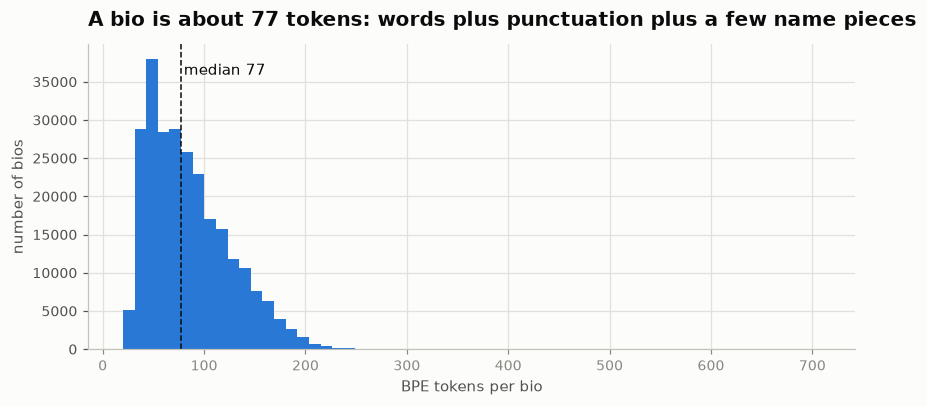

In [27]:
# [3d] encode every bio once
IDS = btok.encode_all(tokenizer, TEXTS)          # IDS[i] = array of token ids of bio i
n_tok = np.array([len(ids) for ids in IDS])
print(f"tokens per bio: median {np.median(n_tok):.0f}, 5–95%: {np.percentile(n_tok, 5):.0f}–{np.percentile(n_tok, 95):.0f}")
fig = plots.hist_with_median(n_tok, f"A bio is about {np.median(n_tok):.0f} tokens: words plus punctuation plus a few name pieces",
                             "BPE tokens per bio")
plt.show()

**What we see (3)**
- **Fast:** the 10,000-token vocabulary is learned in about 5 seconds.
- **Our changes help ([3b]):** the tutorial tokenizer glues punctuation to words (*"t."*, *"s,"*) and keeps
  *Board* ≠ *board*. Ours gives clean words (*board, certified, patients, yoga*).
- **21 of the 28 occupation names are one token ([3c]).** Split: *chiropractor* (chiroprac + tor), *comedian*
  (comed + ian), *rapper*, and the four two-word names, whose words are single tokens.
- **Gender words are clean single tokens:** *she, he, her, his, husband, wife*. So every representation gets direct
  gender features.
- **Rare words are split:** *Brittni* → brit + t + ni, *Utrecht* → ut + re + ch + t. Name pieces can still hint at gender.
- **A bio is ~77 tokens** (5–95%: 35–163).

**Decision.** Keep 10,000 tokens: job words survive whole, and the models stay small.

## 4 · Representations: turning a bio into numbers

**The problem.** A model works with numbers, and it needs every bio as a list of the **same length**, however long
the bio is. The tutorial's trick (*named axes*): make one slot per vocabulary token, so 10,000 slots. Slot *v*
describes token *v* in this bio. The three representations differ only in **what number goes into each slot**:

![representations](../figures/week1/diagrams/representations.png)

| | number in slot *v* | in words |
|---|---|---|
| **R1 indicator** | 1 if token *v* is in the bio, else 0 | *is it there?* |
| **R2 bag-of-words** | how many times token *v* is in the bio | *how often?* |
| **R3 TF-IDF** (ours) | (1 + ln count) × idf(*v*), then the whole list is scaled to length 1 | *how often, how rare, regardless of bio length* |

**What all three throw away: word order.** "*She taught surgeons*" and "*surgeons taught her*" get the same numbers
(the tutorial's *man bites dog* question). Hence the name "bag" of words: cut the bio into words, throw them in a
bag, and count.

**Most slots are 0.** A bio has ~77 tokens, so ~9,950 of its 10,000 slots are empty. Storing all the zeros for 257k
bios would take ≈ 10 GB. A **sparse matrix** (CSR format) stores only the non-zero entries and where they are, which
takes a few hundred MB.

**TF-IDF (R3), explained.** It makes three fixes to raw counts:
1. **Repeats count less.** A word seen 4 times gets 1 + ln 4 = 2.4, not 4. The 4th "patients" tells you less than the 1st.
2. **Common words count less (idf = "inverse document frequency").** $\text{idf}(v) = \ln\frac{1+N}{1+\text{df}(v)} + 1$,
   where df(*v*) = the number of bios containing *v*. A word in nearly every bio (*the, and, he, she*) gets idf ≈ 1;
   a word in 1 of 100 bios gets idf ≈ 5.6. With raw counts, *"the"* would matter as much as *"chiropractic"*.
3. **Length doesn't matter.** Each bio's list is divided by its total size, so long and short bios are on the same scale.

**A leakage trap.** idf is *learned* (it counts bios), so we learn it **only from the training part** of each fold and
then apply it to the validation part. Learning it from all bios would let the test bios influence the features. In
`bib.encoders`, every representation has a `fit` step (learn, training part only) and a `transform` step (apply).
For R1 and R2, `fit` does nothing.

> **This cell:** build one big table once: a row per bio, a column per token, and how often that token occurs in that bio. R1–R3 are all made from this table.

In [28]:
# [4a] the count matrix C: C[i, v] = how often token v occurs in bio i
C = encoders.count_matrix(IDS, V)
words_per_bio = np.diff(C.indptr)                       # number of non-zero slots in each row
print(f"C has {C.shape[0]:,} rows (bios) × {C.shape[1]:,} columns (tokens)")
print(f"non-zero slots per bio: median {np.median(words_per_bio):.0f} of 10,000 "
      f"-> {100 * C.nnz / (C.shape[0] * C.shape[1]):.2f}% of the table is non-zero")
print(f"memory: {(C.data.nbytes + C.indices.nbytes + C.indptr.nbytes) / 1e6:.0f} MB sparse "
      f"vs {C.shape[0] * C.shape[1] * 4 / 1e9:.1f} GB if we stored every zero")

C has 257,081 rows (bios) × 10,000 columns (tokens)
non-zero slots per bio: median 57 of 10,000 -> 0.60% of the table is non-zero
memory: 124 MB sparse vs 10.3 GB if we stored every zero


> **This cell:** look at all non-zero counts: how often is a count 1, 2, 3…? If almost all are 1, then R1 (yes/no) and R2 (counts) are nearly the same thing.

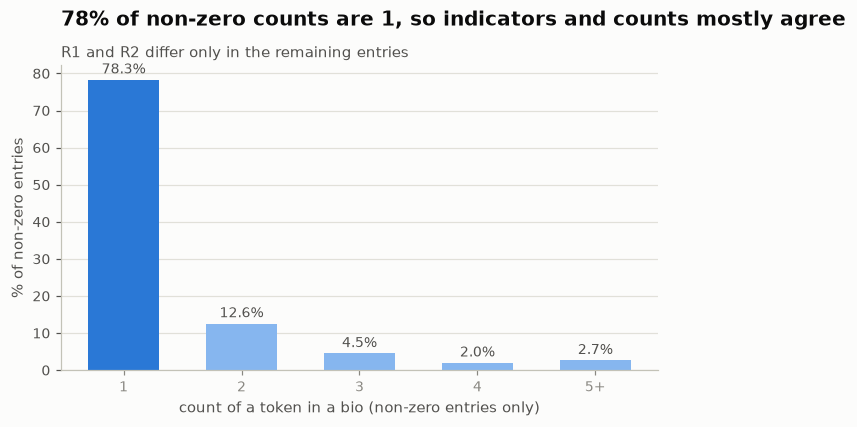

tokens that repeat most: {'▁.': 4.18, '▁,': 4.08, '▁blue': 3.42, '▁and': 3.31, '▁the': 3.24, '▁"': 2.8, '▁of': 2.68, '▁in': 2.55}


In [29]:
# [4b] indicator vs bag-of-words: how often is a count bigger than 1?
counts_capped = np.minimum(C.data.astype(int), 5)
dist = pd.Series(counts_capped).value_counts(normalize=True).sort_index() * 100
dist.index = ["1", "2", "3", "4", "5+"]
fig = plots.count_distribution(dist, f"{dist.iloc[0]:.0f}% of non-zero counts are 1, so indicators and counts mostly agree",
                               "R1 and R2 differ only in the remaining entries")
style.save(fig, FIGURES / "4_count_distribution.png"); plt.show()

# which tokens repeat most inside a bio? (average count in the bios that contain them)
in_bios = np.asarray((C > 0).sum(axis=0)).ravel()
avg_count = np.asarray(C.sum(axis=0)).ravel() / np.maximum(in_bios, 1)
repeaters = pd.Series(avg_count, index=[tokenizer.id_to_token(i) for i in range(V)])[in_bios > 0.01 * C.shape[0]]
print("tokens that repeat most:", repeaters.sort_values(ascending=False).head(8).round(2).to_dict())

> **This cell:** take one nurse bio and show its numbers under R1, R2 and R3 side by side. TF-IDF is learned on the training part of seed 0, fold 0.

She will practice at the NCMC Pulmonary and Sleep Medicine Clinic treating a variety of sleep disorders
including sleep apnea, narcolepsy, insomnia and restless leg syndrome for adults of all ages including older
and disabled adults. 



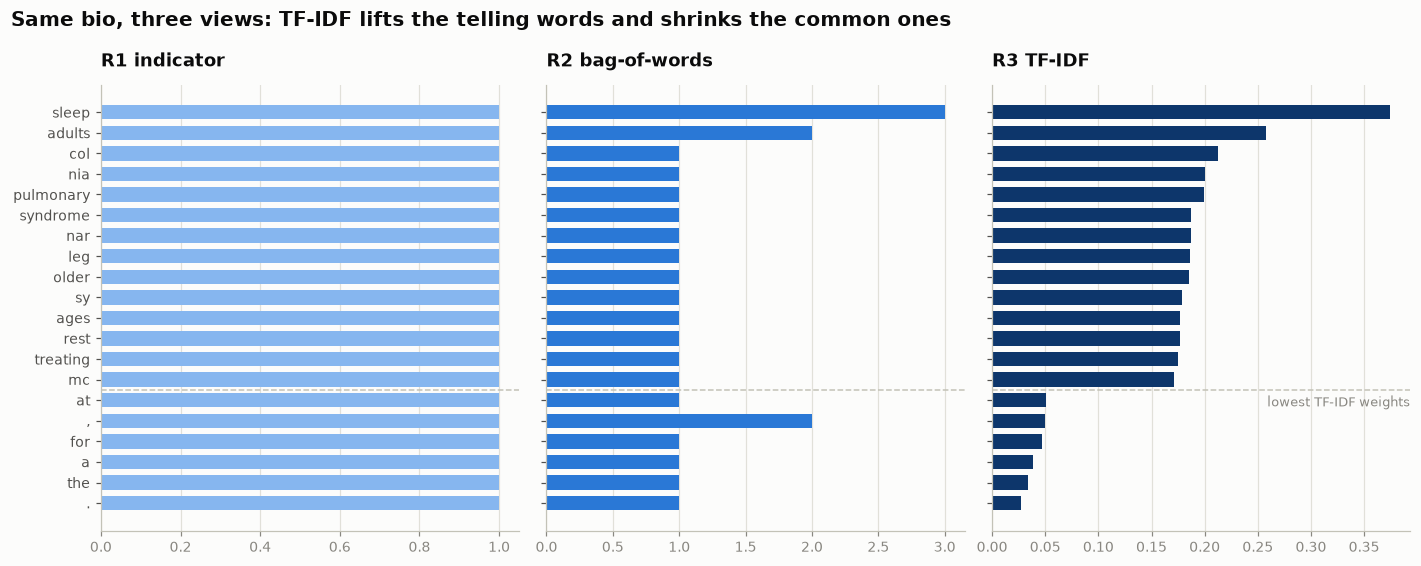

In [30]:
# [4c] one bio, three representations
train0, val0 = FOLDS[SEEDS[0]][0]                       # seed 0, fold 0: training rows, validation rows
tfidf0 = encoders.TfIdf().fit(C[train0])                # learn idf from the training rows only

i = next(j for j in val0 if Y[j] == PROFESSIONS.index("nurse") and 50 <= n_tok[j] <= 80    # a nurse bio that is
          and not re.search(r"\d", TEXTS[j]) and not TEXTS[j].startswith("She graduated with honors"))   # not a template
print(textwrap.fill(TEXTS[i], 110), "\n")
r1 = encoders.Indicator().transform(C[i]).toarray().ravel()
r2 = C[i].toarray().ravel()
r3 = tfidf0.transform(C[i]).toarray().ravel()

present = np.flatnonzero(r2)                            # the tokens in this bio
order = present[np.argsort(-r3[present])]               # sorted by TF-IDF weight
chosen = list(order[:14]) + list(order[-6:])            # 14 highest + 6 lowest
names = [tokenizer.id_to_token(t).replace("▁", "") for t in chosen]
fig = plots.one_bio_three_reps({"indicator": r1[chosen], "bow": r2[chosen], "tfidf": r3[chosen]}, names, 14,
                               "Same bio, three views: TF-IDF lifts the telling words and shrinks the common ones")
style.save(fig, FIGURES / "4_one_bio_three_reps.png"); plt.show()

> **This cell:** show the idf weight of the most common tokens, the pronouns, and some job words.

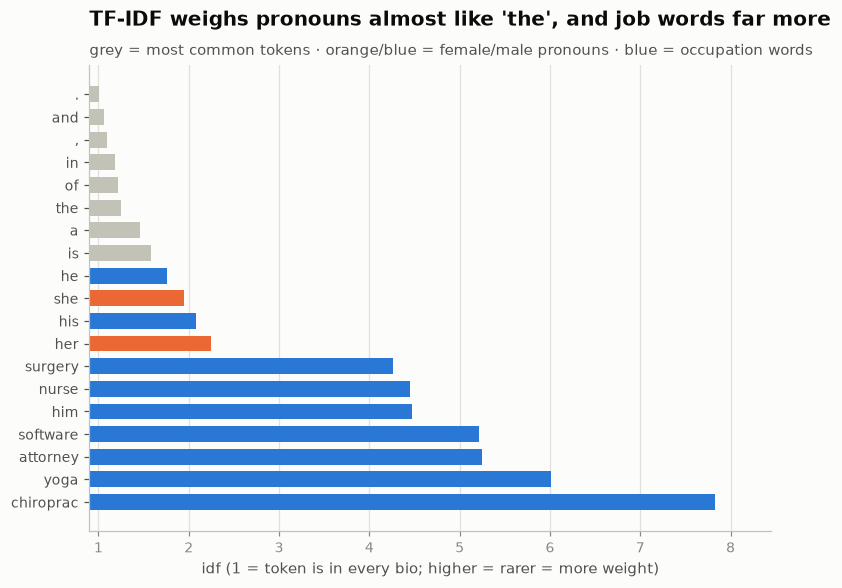

{'▁.': 1.0, '▁and': 1.059999942779541, '▁,': 1.100000023841858, '▁in': 1.190000057220459, '▁of': 1.2200000286102295, '▁the': 1.25, '▁a': 1.4600000381469727, '▁is': 1.5800000429153442, '▁he': 1.7599999904632568, '▁she': 1.9500000476837158, '▁his': 2.0799999237060547, '▁her': 2.240000009536743, '▁surgery': 4.269999980926514, '▁nurse': 4.449999809265137, '▁him': 4.46999979019165, '▁software': 5.21999979019165, '▁attorney': 5.25, '▁yoga': 6.010000228881836, '▁chiroprac': 7.829999923706055}


In [31]:
# [4d] what does idf do to pronouns?
idf = pd.Series(tfidf0.idf, index=[tokenizer.id_to_token(i) for i in range(V)])
pronouns = ["▁she", "▁her", "▁he", "▁his", "▁him"]
job_tokens = ["▁nurse", "▁attorney", "▁yoga", "▁software", "▁surgery", "▁chiroprac"]
most_common = [t for t in idf.sort_values().index if t not in pronouns][:8]
shown = idf[most_common + pronouns + job_tokens].sort_values()
fig = plots.idf_bars(shown, pronouns, job_tokens, "TF-IDF weighs pronouns almost like 'the', and job words far more",
                     "grey = most common tokens · orange/blue = female/male pronouns · blue = occupation words")
style.save(fig, FIGURES / "4_idf_pronouns.png"); plt.show()
print(shown.round(2).to_dict())

**What we see (4)**
- **Size ([4a]):** 257,081 bios × 10,000 tokens. A bio uses a median of **57** different tokens, so only **0.60%** of the
  table is non-zero: **124 MB** stored sparsely, instead of 10.3 GB with all the zeros.
- **R1 vs R2 ([4b]):** **78%** of non-zero counts are 1 (another 13% are 2). The tokens that repeat most are punctuation
  and little words (`.` 4.2 times per bio, `,` 4.1, *and* 3.3, *the* 3.2), plus *blue* (3.4, from the repeated "Blue
  Cross Blue Shield" insurance template). So counts add almost nothing about the *occupation*. **Prediction:** R1 and R2
  will score about the same.
- **One bio ([4c]):** under R1 and R2 every token weighs (about) the same. TF-IDF lifts the rare, telling words of this sleep-clinic nurse
  (*sleep, adults, pulmonary, syndrome*, and pieces of *insomnia / narcolepsy*) and pushes punctuation and
  little words (*at, for, a, the*) to the bottom. *sleep* occurs 3 times: R2 gives it 3× the weight of a single word, TF-IDF only ≈1.8×, because repeats are damped.
- **idf ([4d]):** the most common tokens get idf ≈ 1 (`.` 1.00, *and* 1.06, *the* 1.25). The pronouns are close behind:
  *he* 1.76, *she* 1.95, *his* 2.08, *her* 2.24. Job words get 2–4× more weight: *surgery* 4.27, *nurse* 4.45,
  *software* 5.22, *attorney* 5.25, *yoga* 6.01, *chiroprac* 7.83.

**So what.** TF-IDF stops common tokens, including the pronouns, from dominating a bio's numbers, and it removes length.
Whether that helps accuracy is tested in §8/§9; whether it reduces gender gaps, in §10.

## 5 · Architectures: from numbers to a guess

![architectures](../figures/week1/diagrams/architectures.png)

**What all three models do.** They take the 10,000 numbers of a bio and compute **28 scores**, one per occupation
(higher = more likely). **Softmax** turns the scores into probabilities that add up to 1:
$p(k\mid x) = e^{s_k} / \sum_j e^{s_j}$. The guess is the occupation with the highest probability (the tutorial's
*most probable class* rule).

**What "training" means.** A model has **weights** (numbers it can adjust). Training repeatedly nudges the weights so the
correct occupation gets a higher probability. "How wrong" is measured by the **cross-entropy loss**,
$-\ln p(\text{correct occupation})$. It is 0 if the model is sure and right, and large if it is sure and wrong.

**Inductive bias** = the built-in assumption of a model about what patterns look like. It's the main difference
between A1, A2 and A3.

### 5.1 A1 · Log-linear model (softmax regression)

$$s_k(x) = \mathbf w_k \cdot \mathbf h(x) + b_k$$

- **In words:** every token has one weight per occupation. To score *nurse*, add up the nurse-weights of the bio's
  tokens. It is like a points table: "*patients* +2 for nurse, +1 for physician; *court* +3 for attorney…".
- **Assumption (inductive bias):** clues simply **add up**, and a word always pushes the same way, whatever else the bio
  says. It **cannot** learn "*surgery* means surgeon, *unless* the bio also says *nurse*".
- **Easy to inspect:** the biggest weights for *nurse* show which words push towards nurse. If *she* is among them,
  the model uses gender directly (we check this in §11).
- **One best answer:** training always ends at the same solution (the problem is *convex*), so no randomness.
- **Holding it back (regularisation):** a penalty keeps weights small, so the model doesn't over-trust words seen only
  a few times. `C` controls it: **small `C` = strong penalty (cautious model), large `C` = weak penalty (trusting model).**
- **Code:** scikit-learn's `LogisticRegression`, which works directly on the sparse table.

### 5.2 A2 · MLP with one hidden layer (the tutorial's model, reused unchanged)

$$\mathbf z = \mathrm{ReLU}(\mathbf W_1 \mathbf h(x) + \mathbf b_1) \quad(128\text{ numbers}), \qquad s(x) = \mathbf W_2 \mathbf z + \mathbf b_2$$

- **In words:** first compute 128 in-between numbers, the **hidden layer**. Each one is a learned "detector" that
  combines many words (e.g. "medical + teaching + research words"). Then score the 28 occupations from these 128
  detectors instead of from the raw words.
- **ReLU** = keep positive numbers, set negatives to 0. This small bend is what lets the model learn combinations
  ("this *and* that, but not that"), which A1 cannot.
- **A nice way to see layer 1:** every token gets its own list of 128 numbers (an *embedding*). For a bio, the model
  adds up the lists of its tokens. So a bio's hidden layer is a sum of word meanings.
- **Dropout (10%):** during training, randomly switch off 10% of the detectors each step, so the model can't lean on
  just a few. This reduces overfitting.
- **Randomness:** training starts from random weights, so results depend a little on the seed.

### 5.3 A3 · Deeper MLP (ours): two hidden layers

$$\mathbf z_1 = \mathrm{ReLU}(\mathbf W_1 \mathbf h(x) + \mathbf b_1)\ (256),\quad
\mathbf z_2 = \mathrm{ReLU}(\mathbf W_2 \mathbf z_1 + \mathbf b_2)\ (128),\quad s(x) = \mathbf W_3 \mathbf z_2 + \mathbf b_3$$

- **In words:** the same idea, with a second layer of detectors that combines the first layer's detectors
  ("detectors of detectors").
- **Why we chose it:** the brief suggests "a modification of the MLP". Several occupations share vocabulary
  (physician / surgeon / nurse; professor / everything academic). Does more combining power help separate them?
- **The risk:** about 2.6M weights for 257k bios. It can memorise more, so we use stronger dropout (30%).

### 5.4 How the neural models (A2, A3) are trained

- **Mini-batches:** show the model 128 bios at a time, compute how wrong it is, and nudge all weights a little.
  One pass over all training bios is an **epoch**.
- **Optimiser AdamW:** the rule for "how much to nudge". The **learning rate** is the step size: too small and
  training is slow, too large and it overshoots. AdamW also keeps weights a little small (*weight decay*).
- **Early stopping, explained.** If we train too long the model starts memorising the training bios (**overfitting**).
  So we hide 10% of the *training* part as a mini test ("hold-out"). After every epoch we check macro-F1 on it, keep
  the best version, and stop when 3 epochs in a row bring no improvement.
- **Why not use the validation fold for this?** The tutorial picks the best epoch *on the validation fold* and then
  reports that same fold's score. That's like letting a student pick which exam questions are graded. Our hold-out
  comes from the training part, so the validation fold is used exactly once, for the final score.
- **Why stop on macro-F1 instead of the loss?** Macro-F1 is what we care about, and the loss mostly reflects the big
  classes. In a pilot test, stopping on the loss scored ≈ 0.02 lower.
- **Speed trick:** the first layer only touches the ~60 non-zero slots of each bio, not all 10,000.

> **This cell:** list the three models' sizes and settings, and check our parameter formula against the real models.

In [32]:
# [5a] the three architectures at a glance
from part1.smlp import SparseMLP
arch_table = pd.DataFrame({
    "weights (parameters)": {a: models.param_count(a, V, K) for a in models.ARCHITECTURES},
    "hidden layers": {"loglin": "none", "mlp": "128", "deep": "256 → 128"},
    "dropout": {"loglin": "—", "mlp": 0.1, "deep": 0.3},
    "kept from overfitting by": {"loglin": "penalty C", "mlp": "dropout + early stopping", "deep": "dropout + early stopping"},
})
assert models.n_params(SparseMLP(V, 128, K)) == models.param_count("mlp", V, K)          # formula = real model
assert models.n_params(models.DeepSparseMLP(V, (256, 128), K)) == models.param_count("deep", V, K)
arch_table

,weights (parameters),hidden layers,dropout,kept from overfitting by
loglin,280028,none,—,penalty C
mlp,1283740,128,0.1,dropout + early stopping
deep,2596764,256 → 128,0.3,dropout + early stopping


> **This cell:** train each model once (bag-of-words, seed 0 / fold 0) and plot how the two neural models learn epoch by epoch. About 2 minutes.

loglin: macro-F1 0.7052, accuracy 0.7726, 75s, converged: False


/Users/ishaparanjpe/UvA MSAI/NLP/NLP-Project/Bias-in-Bios/NLP1-Project/src/bib/models.py:88: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:923.)
  return torch.sparse_coo_tensor(idx, torch.from_numpy(X.data.astype(np.float32)), size=X.shape).coalesce()


mlp   : macro-F1 0.7518, accuracy 0.8080, 10s, epochs: 4


deep  : macro-F1 0.7371, accuracy 0.8043, 22s, epochs: 5


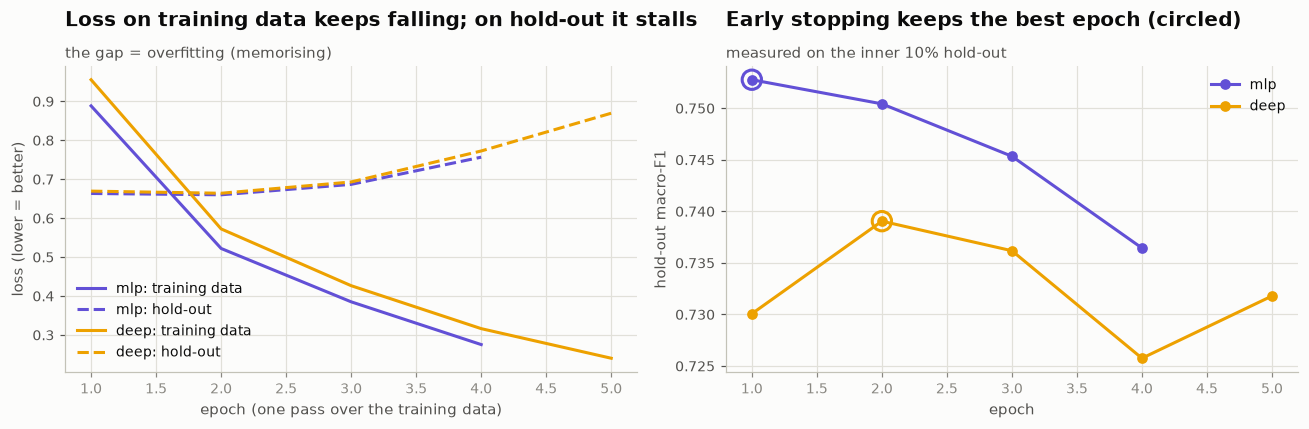

In [33]:
# [5b] one training run per architecture: does training behave?
X_train, X_val, _ = encoders.fold_features("bow", C, train0, val0)
pilot = {}
for arch in models.ARCHITECTURES:
    t0 = time.time()
    clf = models.Classifier(arch, num_classes=K, n_threads=N_THREADS).fit(X_train, Y[train0])
    score = evaluation.scores(Y[val0], clf.predict(X_val))
    pilot[arch] = clf
    print(f"{arch:6s}: macro-F1 {score['macro_f1']:.4f}, accuracy {score['accuracy']:.4f}, {time.time() - t0:.0f}s"
          + (f", converged: {clf.converged}" if arch == "loglin" else f", epochs: {len(clf.history)}"))

fig = plots.training_curves({a: pilot[a].history for a in ("mlp", "deep")})
style.save(fig, FIGURES / "5_training_curves.png"); plt.show()

### 5.5 Making the comparison fair: tune one setting per system

**The problem.** Each model has settings we must choose ourselves (*hyperparameters*). If we used one value for all
systems, it could suit one representation and hurt another. TF-IDF lists are much "smaller" (length 1, against ~9 for
counts), so the same penalty `C` or step size means something different for each.

**The candidates** are the values we try:

| model | setting | candidates | what it means |
|---|---|---|---|
| log-linear | `C` | 0.3, 1, 3 | how much the model may trust single words: 0.3 = cautious, 1 = scikit-learn's default, 3 = trusting |
| MLP, deeper MLP | learning rate | 0.001, 0.003 | the step size of each nudge: 0.001 = AdamW's usual default, 0.003 = 3× bigger steps |

(An earlier run with `C` ∈ {1, 10, 100} picked 1 for every representation, and the large values were slower and often
didn't converge. So the grid is now centred on 1.)

**How (no leakage).** Take the *training* part of seed 0 / fold 0. Split it again 90 / 10, train on the 90% with each
candidate, and score macro-F1 on the 10%. Pick the best per system and use it for **all** folds and seeds. The
validation folds are never looked at. Everything else stays at the defaults in [5a].

> **This cell:** try each candidate value for all 9 systems and keep the best one per system (≈ 8 minutes the first time, saved afterwards).

loaded saved tuning results


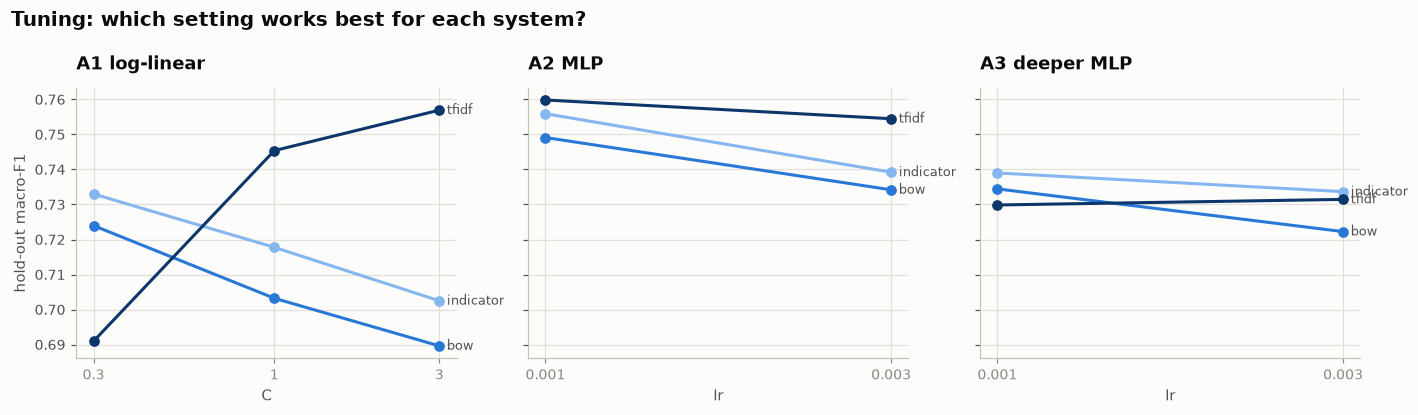

,lr,C
deep_bow,0.001,NaN
deep_indicator,0.001,NaN
deep_tfidf,0.003,NaN
loglin_bow,NaN,0.3
loglin_indicator,NaN,0.3
loglin_tfidf,NaN,3.0
mlp_bow,0.001,NaN
mlp_indicator,0.001,NaN
mlp_tfidf,0.001,NaN


In [34]:
# [5c] tune
TUNE_TABLE, TUNED_PATH = RESULTS / "tuning_table.csv", RESULTS / "tuned_hparams.json"
if TUNED_PATH.exists() and TUNE_TABLE.exists():
    tune_table, TUNED = pd.read_csv(TUNE_TABLE), tuning.load(TUNED_PATH)
    print("loaded saved tuning results")
else:
    tune_table = tuning.tune(C, Y, train0, n_threads=N_THREADS)
    TUNED = tuning.best_params(tune_table)
    tune_table.to_csv(TUNE_TABLE, index=False)
    tuning.save(TUNED, TUNED_PATH)

fig = plots.tuning_lines(tune_table, "Tuning: which setting works best for each system?")
style.save(fig, FIGURES / "5_tuning.png"); plt.show()
pd.DataFrame(TUNED).T

**What we see (5)**
- **Size ([5a]):** log-linear 280,028 weights · MLP 1,283,740 · deeper MLP 2,596,764. Over 90% of each neural model's
  weights sit in the first layer (10,000 tokens × hidden size), i.e. in the word lists ("embeddings").
- **Pilot ([5b], bag-of-words, default settings):** log-linear macro-F1 0.705 (75 s, and it had *not* fully converged
  after 500 rounds), MLP **0.752** (9 s), deeper MLP 0.737 (22 s).
- **The neural models overfit fast.** With 171k training bios, the hold-out score peaks after only **1 epoch (MLP)** and
  **2 epochs (deeper MLP)**. After that, training loss keeps falling while hold-out loss rises: the models start
  memorising. Early stopping caught this and kept the best epoch.
- **Tuning ([5c]) confirms the scale argument from 5.5:**
  - log-linear on indicators and counts: best `C` = **0.3** (more caution);
  - log-linear on TF-IDF: best `C` = **3** (less caution: its numbers are small, so the same penalty hits it harder).
    With `C` = 0.3 it would have scored 0.691 instead of 0.757 on the hold-out, so one shared setting really would have
    been unfair;
  - MLP: learning rate 0.001 for all three; deeper MLP: 0.001, except 0.003 for TF-IDF (0.7315 vs 0.7299, a tiny
    difference).

**So what.** The deeper MLP is behind the MLP already in the pilot, and it overfits a bit sooner. §8 and §9 check
whether that holds across all splits.

## 6 · Metrics

We measure two different things, in two different ways.

**1. How good is a system? One score per fold** (6 per system). These feed the comparison in §9.

| score | in words | role |
|---|---|---|
| **macro-F1** | average F1 over the 28 occupations; each counts equally | **main score** (see 1.4) |
| accuracy | share of bios classified correctly | to compare with published papers |
| balanced accuracy | average recall over the 28 occupations | the average of the recalls used in the fairness analysis |

A **confusion matrix** (rows = true occupation, columns = guessed occupation) shows *where* the mistakes go (§8).

**2. Is it equally good for women and men? Measured on all folds' predictions combined** (used in §10).

![tpr gap](../figures/week1/diagrams/tpr_gap.png)

- **TPR (true positive rate) = recall inside one group:** of the female nurses, how many were guessed "nurse"?
- **TPR gap** for an occupation = TPR of the women − TPR of the men. Positive: women in that job are recognised more
  often. Equal TPRs is a fairness idea called *equality of opportunity* (Hardt et al., 2016): if you *are* a nurse,
  your chance of being recognised as one shouldn't depend on your gender.
- **RMS gap**, one number per system: square each occupation's gap, average, take the square root. Squaring makes
  +0.1 and −0.1 count the same, and big gaps count extra (Romanov et al., 2019; Ravfogel et al., 2020).
- **Why combine the folds' predictions?** Each seed's 3 folds together predict *every* bio exactly once
  ("out-of-fold" predictions). Combining them gives each group its full size: all 88 female rappers instead of ~29
  per fold. Small groups give shaky recall numbers, so bigger is better.
- **Minimum size rule:** an occupation counts in the RMS gap only if both its women and its men number ≥ 10 (all 28 pass).

> **This cell:** check that our metric code gives the same baseline numbers as §1.4.

In [35]:
# [6a] sanity check: the metric code reproduces the §1.4 baselines
shares = np.bincount(Y) / len(Y)
pd.DataFrame({"always 'professor'": evaluation.scores(Y, np.full_like(Y, PROFESSIONS.index("professor"))),
              "random, in class proportions": evaluation.scores(Y, np.random.default_rng(0).choice(K, len(Y), p=shares))}).T

,macro_f1,accuracy,balanced_accuracy
always 'professor',0.016,0.298,0.036
"random, in class proportions",0.036,0.125,0.036


> **This cell:** rebuild the made-up nurse example from the picture and check that the gap comes out as +0.20.

In [36]:
# [6b] the TPR gap on the toy example: 100 female + 100 male nurses
nurse, physician = PROFESSIONS.index("nurse"), PROFESSIONS.index("physician")
y_toy = np.full(200, nurse)                        # all 200 are nurses
g_toy = np.r_[np.ones(100, int), np.zeros(100, int)]   # first 100 women, last 100 men
pred_toy = y_toy.copy()
pred_toy[90:100] = physician                       # 10 women missed  -> TPR women = 0.90
pred_toy[170:200] = physician                      # 30 men missed    -> TPR men   = 0.70
evaluation.tpr_by_gender(y_toy, pred_toy, g_toy, PROFESSIONS).loc[["nurse"]]

,n_female,n_male,pct_female,tpr_female,tpr_male,gap,reported
occupation,,,,,,,
nurse,100,100,50.0,0.9,0.7,0.2,True


> **This cell:** check how big the smallest women/men groups are, and whether all 28 occupations pass the minimum-size rule.

In [37]:
# [6c] group sizes: does every occupation pass the minimum-size rule?
MIN_GROUP = 10
sizes = evaluation.tpr_by_gender(Y, Y, G, PROFESSIONS, min_size=MIN_GROUP)
print(f"occupations included in the RMS gap: {sizes['reported'].sum()} / {K}")
sizes[["n_female", "n_male", "pct_female"]].assign(smaller=lambda d: d[["n_female", "n_male"]].min(axis=1)).sort_values("smaller").head(5).round(1)

occupations included in the RMS gap: 28 / 28


,n_female,n_male,pct_female,smaller
occupation,,,,
rapper,88,823,9.7,88
dj,136,828,14.1,136
yoga_teacher,908,165,84.6,165
paralegal,972,173,84.9,173
interior_designer,765,182,80.8,182


**What we see (6)**
- **The metric code reproduces §1.4 ([6a]):** "always professor" gets macro-F1 0.016, accuracy 0.298, balanced
  accuracy 0.036.
- **The gap code gives the expected +0.20 on the toy example ([6b]).**
- **All 28 occupations pass the minimum-size rule ([6c]).** The smallest groups are 88 female rappers and 136 female DJs.

## 7 · Cross-validation: running all 9 systems

**The whole experiment in plain words** (this is what `cv.run_system` in `src/bib/cv.py` does):

```
for each seed (2):
    for each fold (3):
        1. take the training part and the validation part
        2. build the representation (TF-IDF: learn idf from the training part only)
        3. train the model on the training part, with the setting chosen in §5.5
        4. guess the occupation of every validation bio
        5. score the guesses: macro-F1, accuracy, balanced accuracy
        6. remember the guesses (for the confusion matrix and the fairness analysis)
save everything to results/week1/<system>.pkl
```

- **Same folds for every system.** In §9 we compare systems *fold by fold* (a paired comparison): "on this exact
  split, how much better was A than B?". That only works if all systems saw the same splits.
- **Saved results:** rerunning a cell loads the saved file instead of training again (set `RERUN = True` to force
  retraining).
- **Alternative:** from a terminal, `python scripts/run_grid.py` does the same and writes the same files.

> **This cell:** train every architecture once on bag-of-words (seed 0, fold 0) and time it, to estimate how long the full grid takes.

In [38]:
# [7a] time one fold per architecture and estimate the total
seconds = {}
for arch in models.ARCHITECTURES:
    result, _, _ = cv.train_eval_fold("bow", arch, C, Y, train0, val0, n_threads=N_THREADS,
                                      hp=TUNED[cv.system_name("bow", arch)])
    seconds[arch] = result["seconds"]
    print(f"{arch:6s}: {result['seconds']:.0f}s per fold")
rounds = len(SEEDS) * N_FOLDS * len(encoders.REPRESENTATIONS)
print(f"estimated time for all 9 systems: {sum(seconds.values()) * rounds / 60:.0f} minutes")

loglin: 74s per fold


mlp   : 9s per fold


deep  : 22s per fold
estimated time for all 9 systems: 32 minutes


> **This cell:** run (or load) all 9 systems × 2 seeds × 3 folds, and collect every fold score in one table, `SCORES`. About 30 minutes the first time.

In [39]:
# [7b] run (or load) all 9 systems
RERUN = False
RES = {}
for arch in models.ARCHITECTURES:
    for rep in encoders.REPRESENTATIONS:
        name = cv.system_name(rep, arch)          # e.g. "mlp_tfidf"
        RES[name] = cv.run_system(rep, arch, C, Y, FOLDS, RESULTS, rerun=RERUN, n_threads=N_THREADS, hp=TUNED[name])
SCORES = pd.concat([r["scores"] for r in RES.values()], ignore_index=True)
print(f"{len(RES)} systems, {len(SCORES)} fold scores")
SCORES.head(3)

9 systems, 54 fold scores


,system,rep,arch,seed,fold,macro_f1,accuracy,balanced_accuracy,seconds,converged,epochs
0,loglin_indicator,indicator,loglin,0,0,0.733,0.794,0.706,32.322,True,None
1,loglin_indicator,indicator,loglin,0,1,0.722,0.792,0.695,35.337,True,None
2,loglin_indicator,indicator,loglin,0,2,0.727,0.793,0.697,36.038,True,None


**What we see (7)**
- **Time per fold ([7a], bag-of-words):** log-linear 75 s, MLP 9 s, deeper MLP 25 s → estimate 33 min. The real grid
  took ≈ 25 minutes.
- Per system ([8a], last column): the MLPs are fastest (9–14 s per fold), log-linear is the slowest on counts (74 s).
- **Convergence:** the log-linear model on counts (`loglin_bow`) did **not** fully converge within 500 rounds on any fold.
  The other log-linear systems did. Its score may be slightly too low; this is a limitation to mention (raw counts make
  the optimisation harder; TF-IDF and indicators are better scaled).

## 8 · Results

**How to read this section**
- **[8a] table:** average ± standard deviation over the 6 fold scores of each system. The standard deviation (std)
  shows how much a score moves from one split to another. Differences smaller than that shouldn't be trusted
  without §9.
- **[8b] dots:** every fold score is a dot; the black bar is the average.
- **[8c] 3 × 3 grid:** average macro-F1. Read along a **row** to compare models, down a **column** to compare
  representations.
- **[8d–8e]:** *which* occupations the best system gets right or wrong.

> **This cell:** average the 6 fold scores of each system and find the best system.

In [40]:
# [8a] mean ± std per system
order = [cv.system_name(r, a) for a in models.ARCHITECTURES for r in encoders.REPRESENTATIONS]
mean = SCORES.groupby("system")[list(evaluation.METRICS)].mean().loc[order]
std = SCORES.groupby("system")[list(evaluation.METRICS)].std().loc[order]
BEST = mean["macro_f1"].idxmax()
print("best system by mean macro-F1:", BEST)
summary = mean.round(4).astype(str) + " ± " + std.round(4).astype(str)
summary["seconds per fold"] = SCORES.groupby("system")["seconds"].mean().loc[order].round(0)
summary

best system by mean macro-F1: mlp_tfidf


,macro_f1,accuracy,balanced_accuracy,seconds per fold
system,,,,
loglin_indicator,0.7275 ± 0.004,0.7935 ± 0.0012,0.6994 ± 0.0041,35.0
loglin_bow,0.7193 ± 0.0036,0.7863 ± 0.0014,0.691 ± 0.004,74.0
loglin_tfidf,0.7489 ± 0.0025,0.8069 ± 0.0009,0.7129 ± 0.0037,37.0
mlp_indicator,0.7488 ± 0.001,0.8093 ± 0.0015,0.7247 ± 0.0035,9.0
mlp_bow,0.7469 ± 0.0029,0.8071 ± 0.001,0.7199 ± 0.0038,10.0
mlp_tfidf,0.7543 ± 0.0018,0.8109 ± 0.001,0.73 ± 0.0045,14.0
deep_indicator,0.7375 ± 0.0023,0.8071 ± 0.0021,0.7203 ± 0.0028,26.0
deep_bow,0.7368 ± 0.0031,0.8063 ± 0.0015,0.7161 ± 0.0072,28.0
deep_tfidf,0.7296 ± 0.0014,0.8032 ± 0.002,0.7111 ± 0.0084,26.0


> **This cell:** plot every fold score of every system.

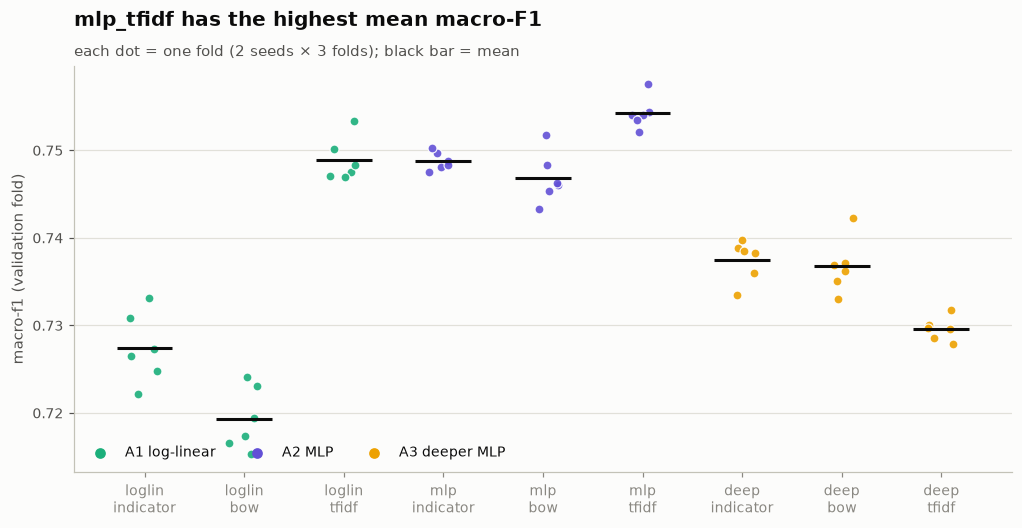

In [41]:
# [8b] every fold score
fig = plots.fold_scores(SCORES, order, f"{BEST} has the highest mean macro-F1",
                        f"each dot = one fold ({len(SEEDS)} seeds × {N_FOLDS} folds); black bar = mean")
style.save(fig, FIGURES / "8_fold_scores.png"); plt.show()

> **This cell:** put the 9 mean macro-F1 scores into a 3 × 3 grid, plus the average of each row and column.

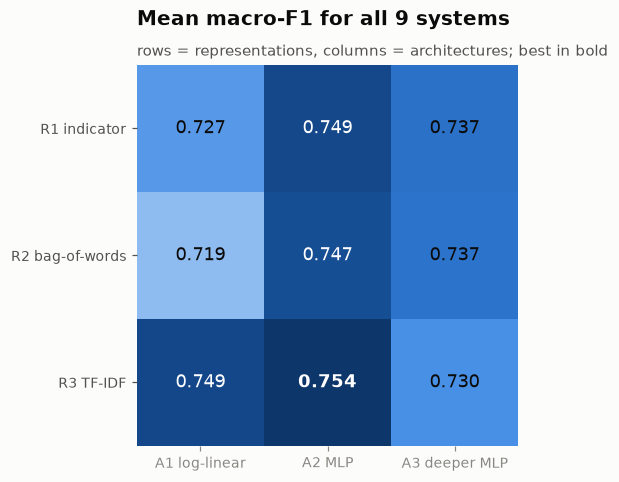

average per representation: {'indicator': 0.7379, 'bow': 0.7343, 'tfidf': 0.7443}
average per architecture:   {'loglin': 0.7319, 'mlp': 0.75, 'deep': 0.7346}


In [42]:
# [8c] the 3 × 3 grid
grid = SCORES.groupby(["rep", "arch"])["macro_f1"].mean().unstack()               # rows = rep, columns = arch
grid = grid.loc[list(encoders.REPRESENTATIONS), list(models.ARCHITECTURES)]
fig = plots.grid_heatmap(grid, "Mean macro-F1 for all 9 systems", "rows = representations, columns = architectures; best in bold")
style.save(fig, FIGURES / "8_grid_heatmap.png"); plt.show()
print("average per representation:", grid.mean(axis=1).round(4).to_dict())
print("average per architecture:  ", grid.mean(axis=0).round(4).to_dict())

> **This cell:** compute the F1 of every occupation for the best system, and compare it with the keyword reliability from §1.9.

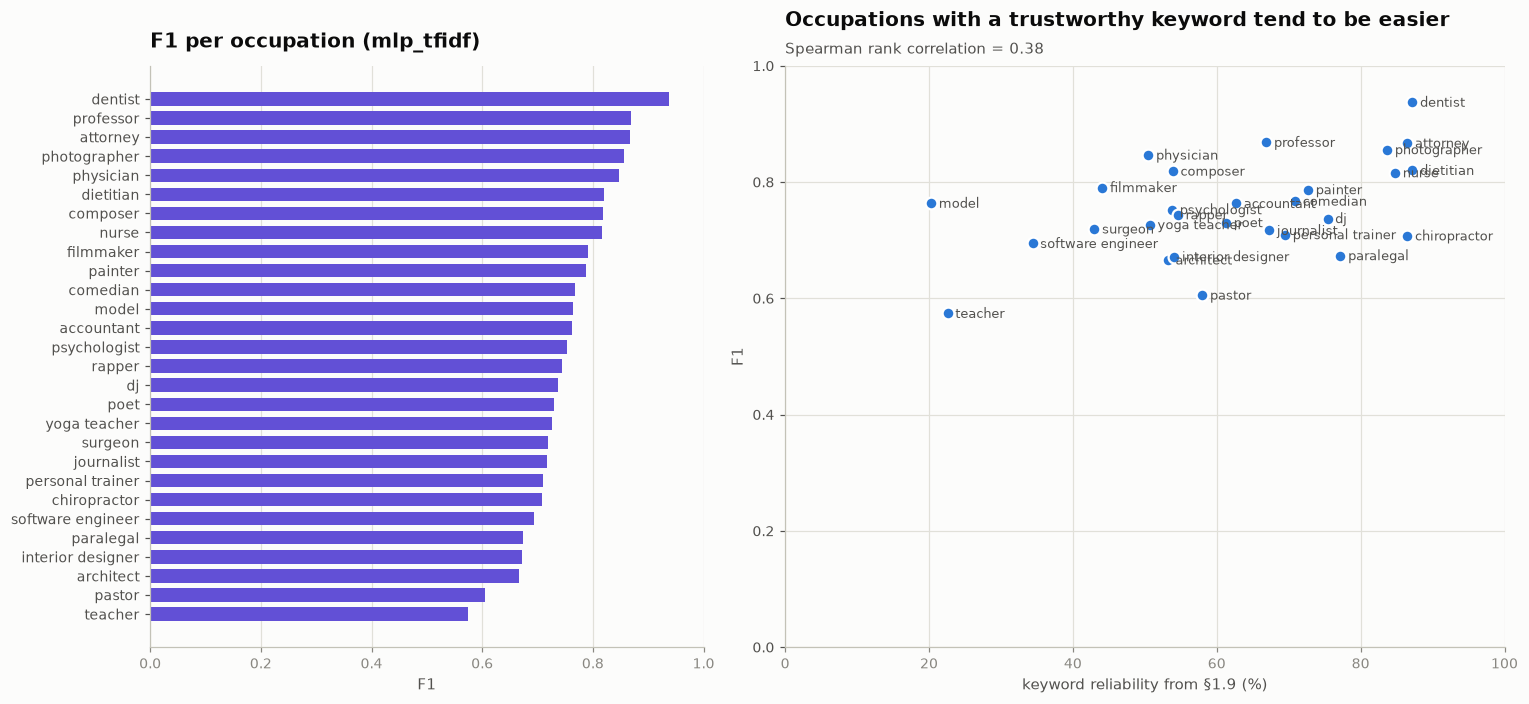

In [43]:
# [8d] per-occupation F1 of the best system vs the keyword probe
oof = RES[BEST]["oof"][SEEDS[0]]                     # seed 0: every bio's out-of-fold guess
f1_occ = evaluation.per_class_f1(Y, oof, PROFESSIONS)
rho = f1_occ.corr(keyword_probe["reliability (%)"], method="spearman")
fig = plots.f1_vs_keyword(f1_occ, keyword_probe["reliability (%)"], style.ARCH_COLORS[RES[BEST]["arch"]],
                          f"F1 per occupation ({BEST})", "Occupations with a trustworthy keyword tend to be easier",
                          f"Spearman rank correlation = {rho:.2f}")
style.save(fig, FIGURES / "8_per_class_f1.png"); plt.show()

> **This cell:** draw the confusion matrix of the best system and list its 12 most common mistakes.

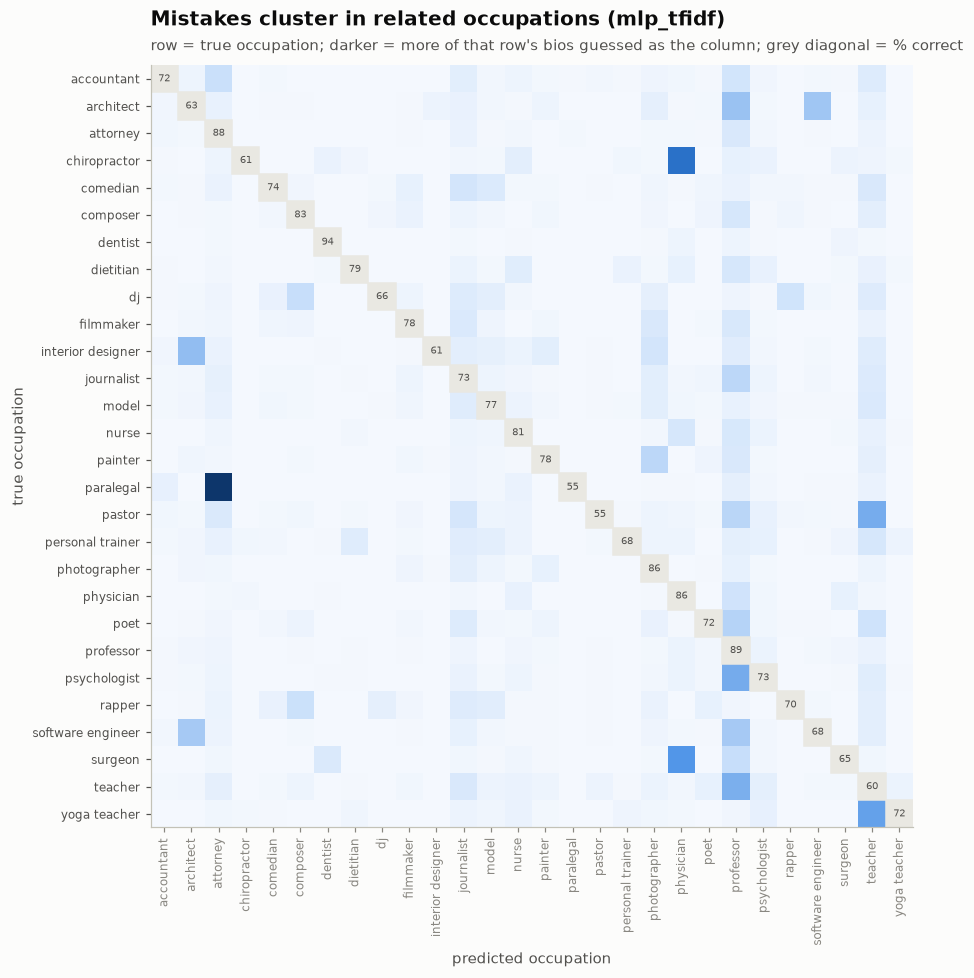

,true,predicted as,% of true class,bios
0,paralegal,attorney,34.0,389
1,chiropractor,physician,23.6,401
2,surgeon,physician,18.2,1601
3,yoga_teacher,teacher,16.5,177
4,psychologist,professor,15.0,1792
5,pastor,teacher,15.0,245
6,teacher,professor,14.5,1523
7,interior_designer,architect,12.4,117
8,architect,professor,11.7,764
9,architect,software_engineer,11.1,725


In [44]:
# [8e] where do the errors go?
cm = evaluation.normalized_confusion(Y, oof, K)
fig = plots.confusion_heatmap(cm, PROFESSIONS, f"Mistakes cluster in related occupations ({BEST})",
                              "row = true occupation; darker = more of that row's bios guessed as the column; grey diagonal = % correct")
style.save(fig, FIGURES / "8_confusion.png"); plt.show()
evaluation.top_confusions(Y, oof, PROFESSIONS, n=12).round(1)

**What we see (8)**
- **Best system: `mlp_tfidf`** with macro-F1 **0.754 ± 0.002** (accuracy 0.811, balanced accuracy 0.730). All 9 systems
  are far above the baselines (0.04 macro-F1 / 0.30 accuracy): from 0.719 (`loglin_bow`) to 0.754.
- **Fold-to-fold noise is small:** std 0.001–0.004 (median 0.0025). So differences of 0.01 or more are well above noise.
- **Models (columns of [8c]):** the MLP is best for every representation (average 0.750). The deeper MLP (0.735) and
  log-linear (0.732) are behind. **A second hidden layer did not help.** It even hurt with TF-IDF (0.730 vs 0.754).
- **Representations (rows):** indicator (0.738) ≈ bag-of-words (0.734), as predicted from [4b]. TF-IDF is best on
  average (0.744), but mainly because it helps the **log-linear model a lot** (0.749 vs 0.727 / 0.719). With TF-IDF, the
  simple log-linear model is almost as good as the MLP.
- **Per occupation ([8d]):** easiest dentist (F1 0.94), professor (0.87), attorney (0.87), photographer (0.86), physician
  (0.85). Hardest teacher (0.57), pastor (0.61), architect (0.67), interior designer (0.67), paralegal (0.67). Keyword
  reliability from §1.9 predicts this only moderately (Spearman ρ = 0.38). The model also uses many words beyond the job
  name (e.g. *model* scores 0.76 despite its unreliable keyword).
- **Main mistakes ([8e]):** paralegal → attorney (34% of paralegals!), chiropractor → physician (24%), surgeon → physician
  (18%), yoga teacher → teacher (17%), psychologist → professor (15%), pastor → teacher (15%), teacher → professor (15%),
  interior designer → architect (12%). These are the "shared vocabulary" pairs predicted in 1.3 and 1.9. *Professor*
  absorbs many academic-sounding bios.
- **Accuracy vs macro-F1:** accuracy is ≈ 0.06 higher, because the big classes are easy and the small ones pull
  macro-F1 down.

**Next:** are these differences real and big enough to matter (§9)? And are they equally good for women and men (§10)?

## 9 · Bayesian comparison: are the differences real, and do they matter?

**The question.** System B scores 0.004 higher than A on average. Is B really better, or did it get lucky on these
particular splits? And even if it is better, is 0.004 enough to *care*?

**The idea in plain words** (Benavoli et al., 2017; the tutorial's `BenavoliCorrelatedT`):
1. For each of the 6 splits, compute **difference = score(B) − score(A)**. Same split, so it's a fair head-to-head.
2. From those 6 differences, the method computes a **posterior**: a curve showing which values of the *true average
   difference* are believable, given what we saw. A narrow curve = we're fairly sure; a wide curve = unsure.
3. We agree beforehand on a **ROPE (region of practical equivalence)**: differences so small that, in practice, the
   two systems count as equally good. We use **±0.01 macro-F1**.
4. Then we read off three numbers: the share of the curve **left of the ROPE** = P(A better), **inside** =
   P(practically equal), **right** = P(B better). They add up to 1.

**"Correlated" t-test, why the correction?** The 3 folds of one seed share training bios (each pair of training
parts overlaps by half), so their scores move together and are not 3 independent pieces of evidence. The method
inflates the uncertainty to account for this (the Nadeau–Bengio correction; Corani & Benavoli, 2015).

**Why a ROPE of 0.01 (one macro-F1 point)?**
- **Practical meaning:** +0.01 macro-F1 means, e.g., *every* occupation's F1 rises by one point, or one occupation's
  F1 rises by 0.28 (= 0.01 × 28). Below that, we wouldn't switch systems in a real application, especially when the
  cheaper or simpler one is on the "worse" side.
- **Relative to the noise:** it's 4× the typical fold-to-fold standard deviation (median 0.0025, see [9a]), so we don't
  call noise "a difference".
- **Relative to the tutorial:** the tutorial uses 0.005 for *accuracy*. Macro-F1 moves more, because small classes swing
  it, so a slightly wider ROPE is reasonable.
- **Sensitivity check:** we also report ROPE = 0.005 and 0.02, to show whether the conclusions depend on the choice.

**What we compare (18 pairs).** Changing *one* thing at a time: in every row of the grid the 3 model pairs (same
representation), and in every column the 3 representation pairs (same model).

**Reading a verdict.** We call a result clear when one region has ≥ 95% of the probability. Otherwise it's "unsure".

> **This cell:** collect each system's 6 fold scores in a fixed order (seed 0 folds 0–2, then seed 1 folds 0–2), so A and B are compared split by split.

In [45]:
# [9a] fold scores in a fixed order, and the fold-to-fold noise
def fold_scores_of(name, metric="macro_f1"):
    s = SCORES[SCORES["system"] == name].sort_values(["seed", "fold"])
    return s[metric].to_numpy()

ROPE = 0.01
print("fold-to-fold std of macro-F1 per system:", SCORES.groupby("system")["macro_f1"].std().round(4).to_dict())
print(f"median: {SCORES.groupby('system')['macro_f1'].std().median():.4f}  (ROPE = {ROPE})")

fold-to-fold std of macro-F1 per system: {'deep_bow': 0.0031, 'deep_indicator': 0.0023, 'deep_tfidf': 0.0014, 'loglin_bow': 0.0036, 'loglin_indicator': 0.004, 'loglin_tfidf': 0.0025, 'mlp_bow': 0.0029, 'mlp_indicator': 0.001, 'mlp_tfidf': 0.0018}
median: 0.0025  (ROPE = 0.01)


> **This cell:** for each of the 18 pairs, compute the posterior and the three probabilities, for three ROPE sizes.

In [46]:
# [9b] 18 comparisons x 3 ROPE sizes
PAIRS = []
for rep in encoders.REPRESENTATIONS:                       # same representation, different model
    PAIRS += [(f"loglin_{rep}", f"mlp_{rep}"), (f"loglin_{rep}", f"deep_{rep}"), (f"mlp_{rep}", f"deep_{rep}")]
for arch in models.ARCHITECTURES:                          # same model, different representation
    PAIRS += [(f"{arch}_indicator", f"{arch}_bow"), (f"{arch}_indicator", f"{arch}_tfidf"), (f"{arch}_bow", f"{arch}_tfidf")]

def verdict(p_a, p_eq, p_b, a, b):
    if p_b >= 0.95: return f"{b} better"
    if p_a >= 0.95: return f"{a} better"
    if p_eq >= 0.95: return "practically equal"
    return "unsure"

rows = []
for a, b in PAIRS:
    post = analysis.BenavoliCorrelatedT(fold_scores_of(a), fold_scores_of(b), runs=len(SEEDS), names=[a, b])
    for rope in (0.005, 0.01, 0.02):
        p_a, p_eq, p_b = post.probs(rope)
        rows.append({"A": a, "B": b, "ROPE": rope, "mean diff (B−A)": post.mean_diff, "posterior std": post.std,
                     "P(A better)": p_a, "P(equal)": p_eq, "P(B better)": p_b, "verdict": verdict(p_a, p_eq, p_b, a, b)})
BAYES = pd.DataFrame(rows)
main = BAYES[BAYES["ROPE"] == ROPE].reset_index(drop=True)
main.round(3)

,A,B,ROPE,mean diff (B−A),posterior std,P(A better),P(equal),P(B better),verdict
0,loglin_indicator,mlp_indicator,0.01,0.021,0.003,0.000,0.004,0.996,mlp_indicator better
1,loglin_indicator,deep_indicator,0.01,0.010,0.002,0.000,0.495,0.505,unsure
2,mlp_indicator,deep_indicator,0.01,-0.011,0.002,0.764,0.236,0.000,unsure
3,loglin_bow,mlp_bow,0.01,0.028,0.002,0.000,0.000,1.000,mlp_bow better
4,loglin_bow,deep_bow,0.01,0.017,0.002,0.000,0.010,0.990,deep_bow better
5,mlp_bow,deep_bow,0.01,-0.010,0.003,0.511,0.488,0.001,unsure
6,loglin_tfidf,mlp_tfidf,0.01,0.005,0.001,0.000,0.998,0.002,practically equal
7,loglin_tfidf,deep_tfidf,0.01,-0.019,0.002,0.994,0.006,0.000,loglin_tfidf better
8,mlp_tfidf,deep_tfidf,0.01,-0.025,0.002,1.000,0.000,0.000,mlp_tfidf better
9,loglin_indicator,loglin_bow,0.01,-0.008,0.001,0.024,0.976,0.000,practically equal


> **This cell:** draw the three probabilities of every comparison as one stacked bar each (ROPE = 0.01).

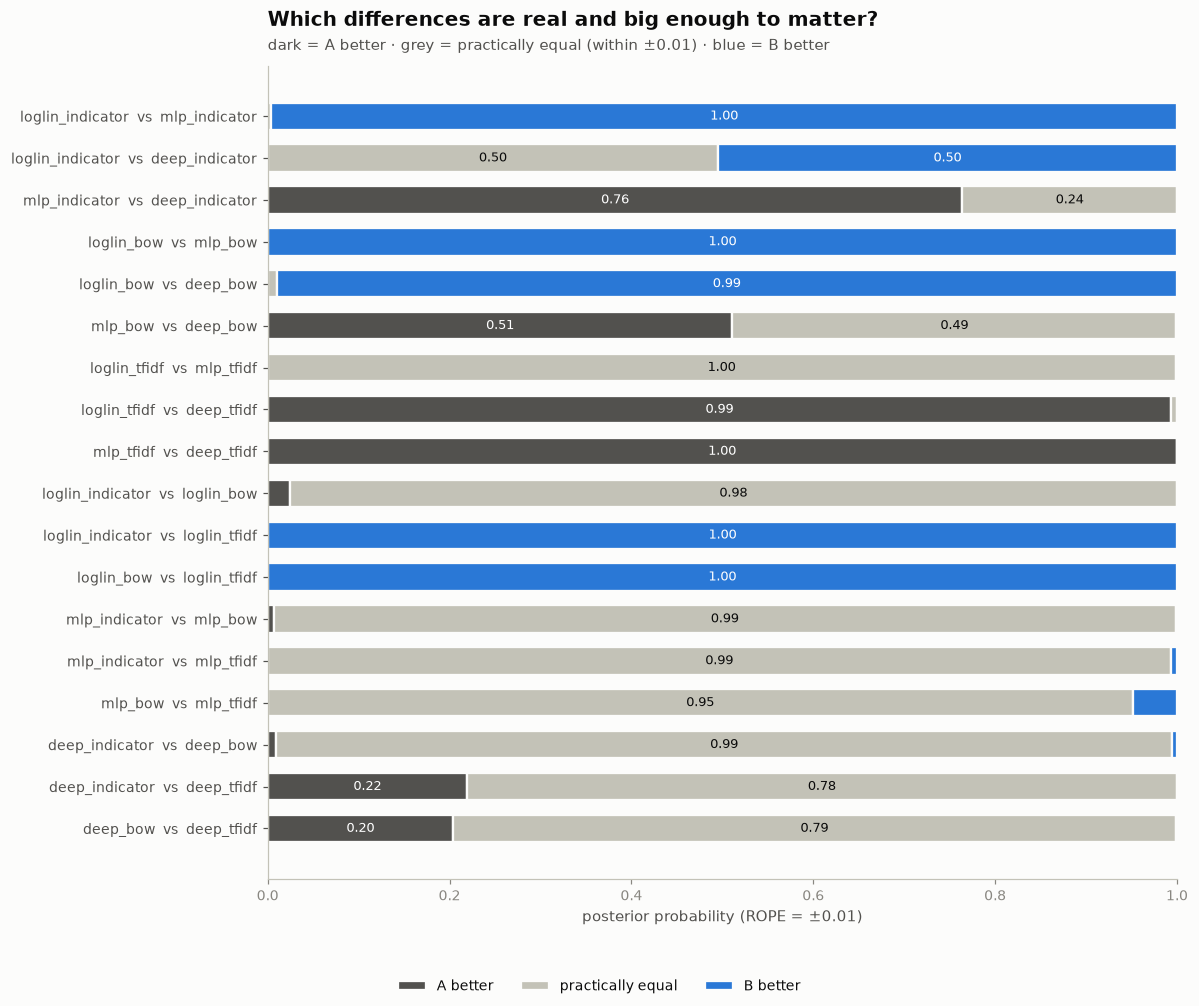

In [47]:
# [9c] all 18 comparisons at a glance
fig = plots.comparison_bars(main, ROPE, "Which differences are real and big enough to matter?",
                            "dark = A better · grey = practically equal (within ±0.01) · blue = B better")
style.save(fig, FIGURES / "9_comparisons.png"); plt.show()

> **This cell:** show the full posterior curve (with the ROPE shaded) for three comparisons that answer our main questions.

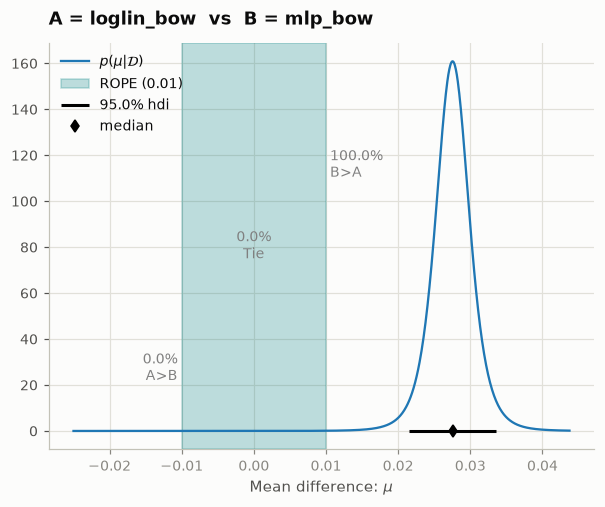

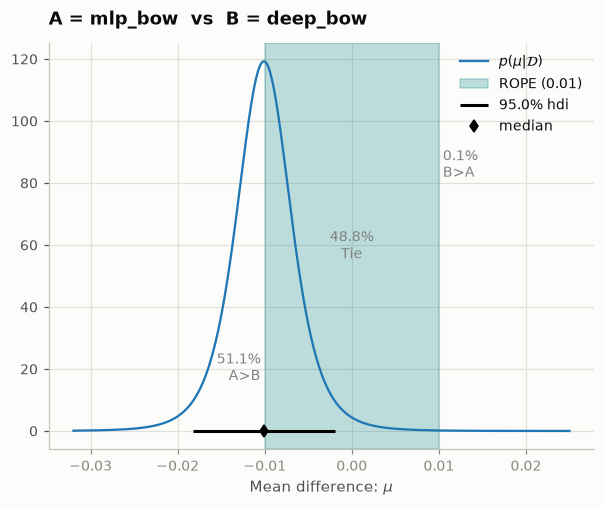

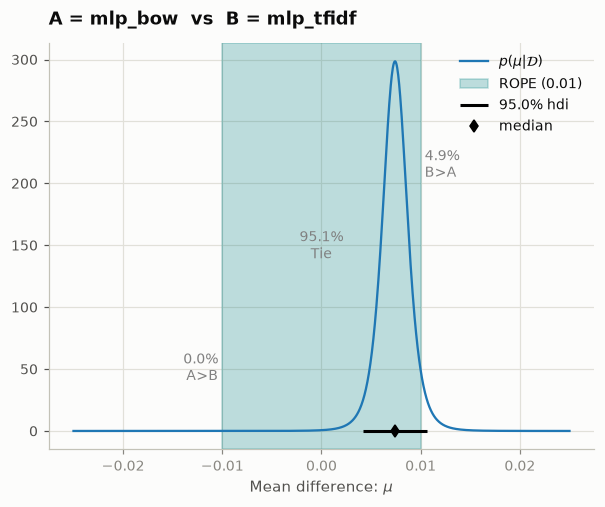

In [48]:
# [9d] three posterior curves (tutorial's plot: curve = believable values of the mean difference B − A)
best_arch = RES[BEST]["arch"]
for a, b in [("loglin_bow", "mlp_bow"),                       # does a hidden layer help?
             ("mlp_bow", "deep_bow"),                         # does a second hidden layer help?
             (f"{best_arch}_bow", f"{best_arch}_tfidf")]:     # does TF-IDF help (for the best model type)?
    post = analysis.BenavoliCorrelatedT(fold_scores_of(a), fold_scores_of(b), runs=len(SEEDS), names=[a, b])
    fig, ax = post.plot(ROPE)
    ax.set_title(f"A = {a}  vs  B = {b}", fontsize=11.5)
    style.save(fig, FIGURES / f"9_posterior_{a}_vs_{b}.png"); plt.show()

> **This cell:** check whether the verdicts change when the ROPE is half or twice as wide.

In [49]:
# [9e] sensitivity: verdict per ROPE size
BAYES.assign(pair=BAYES["A"] + "  vs  " + BAYES["B"]).pivot(index="pair", columns="ROPE", values="verdict").loc[
    [f"{a}  vs  {b}" for a, b in PAIRS]]

ROPE,0.005,0.010,0.020
pair,,,
loglin_indicator vs mlp_indicator,mlp_indicator better,mlp_indicator better,unsure
loglin_indicator vs deep_indicator,deep_indicator better,unsure,practically equal
mlp_indicator vs deep_indicator,mlp_indicator better,unsure,practically equal
loglin_bow vs mlp_bow,mlp_bow better,mlp_bow better,mlp_bow better
loglin_bow vs deep_bow,deep_bow better,deep_bow better,unsure
mlp_bow vs deep_bow,unsure,unsure,practically equal
loglin_tfidf vs mlp_tfidf,unsure,practically equal,practically equal
loglin_tfidf vs deep_tfidf,loglin_tfidf better,loglin_tfidf better,unsure
mlp_tfidf vs deep_tfidf,mlp_tfidf better,mlp_tfidf better,mlp_tfidf better


**How to read the curve in [9d].** The x-axis is the true average difference B − A (positive = B better). The blue
curve is the posterior: higher = more believable. The shaded band is the ROPE. The black bar under the curve is the
**95% HDI** (highest density interval): the narrowest range that holds 95% of the belief. The percentages are the
areas left of, inside and right of the ROPE.

**What we see (9)** (ROPE = ±0.01, "clear" = ≥ 95% probability)
- **Does a hidden layer help? Yes, unless we use TF-IDF.** MLP vs log-linear: +0.021 on indicators (P = 0.996) and +0.028 on
  counts (P = 1.00). But on TF-IDF the difference is only +0.005 → **practically equal** (P = 0.998). TF-IDF closes the gap
  between the simple and the neural model.
- **Does a second hidden layer help? No.** Deeper MLP vs MLP: −0.011 (indicators), −0.010 (counts): "unsure" whether that's
  worse or equal. And −0.025 on TF-IDF: **MLP clearly better** (P = 1.00). Our own architecture did not pay off.
- **Indicators vs counts: practically equal for all three models** (P(equal) = 0.98, 0.99, 0.99), exactly as predicted from
  [4b] (78% of counts are 1).
- **TF-IDF vs the others:** clearly better for log-linear (+0.021 vs indicators, +0.030 vs counts; P = 1.00). Practically
  equal for the MLP (P = 0.99 / 0.95). Unsure for the deeper MLP.
- **Sensitivity ([9e]):** the main conclusions survive all three ROPE sizes. TF-IDF beats counts for log-linear, MLP beats
  log-linear on counts, and MLP beats the deeper MLP on TF-IDF at every ROPE. With a stricter ROPE (0.005) many "equal"s
  become "unsure" or small wins. With a looser one (0.02) most become "equal". So small differences (< 0.01) are real but
  minor, and our story doesn't hinge on the exact ROPE.

**So what.** For this task, *how you weight the words* (TF-IDF) and *one* hidden layer each help. They help in a similar
way, so combining them adds little (0.749 → 0.754). Depth beyond one layer doesn't help. Since `mlp_tfidf` and
`loglin_tfidf` are practically equal, the simpler, faster-to-explain log-linear model would be a perfectly reasonable choice.

## 10 · Fairness: does each system work equally well for women and men?

For every system we take its out-of-fold guesses (each seed predicts every bio once), compute recall for women and
for men in each occupation, and average over the 2 seeds. Then:
- **[10a]** one fairness summary per system: RMS gap, and the correlation between gap and % women;
- **[10b]** the gap for every occupation against its % women, for the best system (like De-Arteaga et al., Fig. 2);
- **[10c]** which gender is missed in each occupation, and *what they are mistaken for*.

**Our hypothesis (from 1.5):** occupations dominated by women get positive gaps (women recognised more often), and
occupations dominated by men get negative gaps. That would show up as a positive correlation in [10b].

> **This cell:** compute, for every system, the gap per occupation (averaged over both seeds), the RMS gap, and how strongly the gap follows % women.

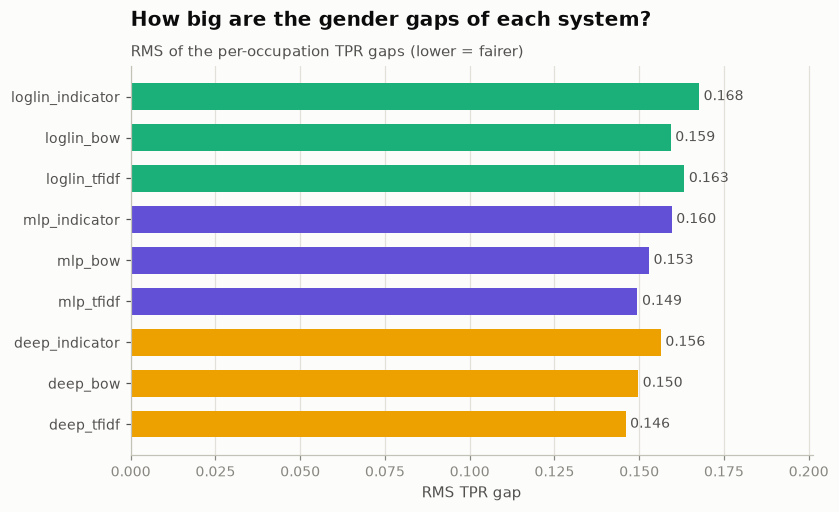

,macro-F1,RMS gap,"corr(gap, % women)"
loglin_indicator,0.727,0.168,0.895
loglin_bow,0.719,0.159,0.885
loglin_tfidf,0.749,0.163,0.887
mlp_indicator,0.749,0.160,0.879
mlp_bow,0.747,0.153,0.866
mlp_tfidf,0.754,0.149,0.863
deep_indicator,0.737,0.156,0.875
deep_bow,0.737,0.150,0.856
deep_tfidf,0.730,0.146,0.822


In [50]:
# [10a] fairness summary for all 9 systems
def gap_table(name):
    """Recall of women and men per occupation for one system, averaged over the seeds."""
    tables = [evaluation.tpr_by_gender(Y, RES[name]["oof"][s], G, PROFESSIONS, MIN_GROUP) for s in SEEDS]
    avg = sum(t[["tpr_female", "tpr_male", "gap"]] for t in tables) / len(tables)
    return tables[0][["n_female", "n_male", "pct_female", "reported"]].join(avg)

GAPS = {name: gap_table(name) for name in order}
fair = pd.DataFrame({
    "macro-F1": mean["macro_f1"],
    "RMS gap": {n: evaluation.rms_gap(t) for n, t in GAPS.items()},
    "corr(gap, % women)": {n: t.loc[t["reported"], "gap"].corr(t.loc[t["reported"], "pct_female"]) for n, t in GAPS.items()},
}).loc[order]
fig = plots.system_bars(fair["RMS gap"], "How big are the gender gaps of each system?",
                        "RMS of the per-occupation TPR gaps (lower = fairer)", "RMS TPR gap")
style.save(fig, FIGURES / "10_rms_gap.png"); plt.show()
fair.round(3)

> **This cell:** plot, for the best system, each occupation's gap against its % women, with the correlation.

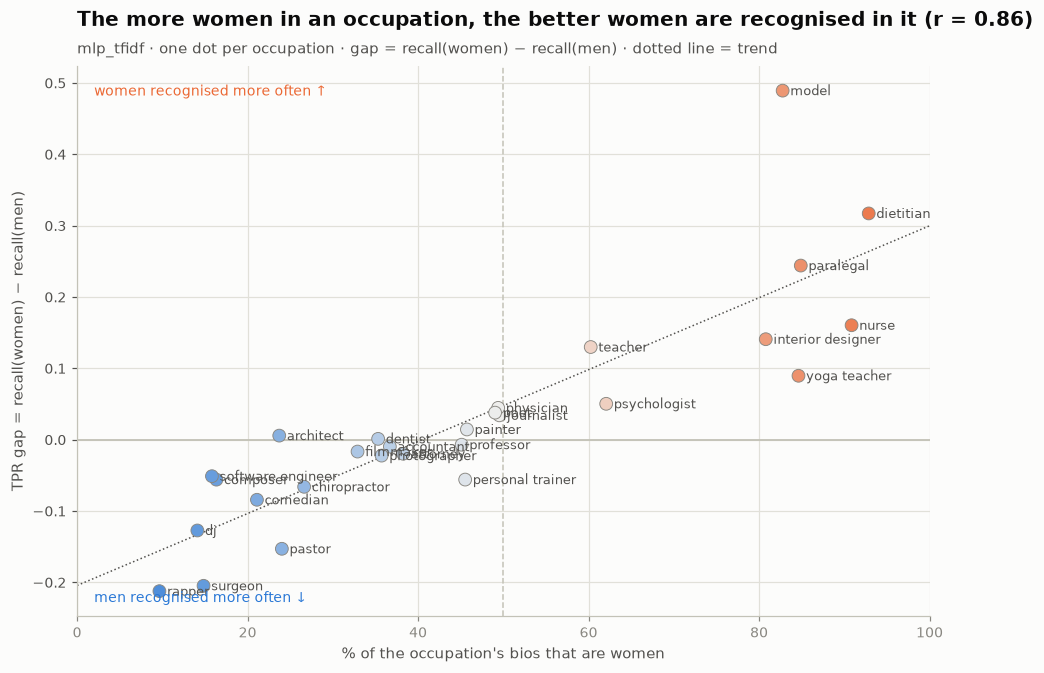

,pct_female,tpr_female,tpr_male,gap
occupation,,,,
rapper,9.660,0.511,0.724,-0.212
surgeon,14.835,0.480,0.684,-0.205
pastor,24.022,0.422,0.575,-0.153
dj,14.108,0.559,0.686,-0.127
comedian,21.099,0.673,0.757,-0.084
chiropractor,26.635,0.569,0.635,-0.066
composer,16.346,0.785,0.841,-0.056
personal_trainer,45.523,0.636,0.692,-0.056
software_engineer,15.819,0.644,0.695,-0.051


In [51]:
# [10b] gap vs % women for the best system
t = GAPS[BEST]
r = t.loc[t["reported"], "gap"].corr(t.loc[t["reported"], "pct_female"])
fig = plots.gap_vs_female(t, f"The more women in an occupation, the better women are recognised in it (r = {r:.2f})",
                          f"{BEST} · one dot per occupation · gap = recall(women) − recall(men) · dotted line = trend")
style.save(fig, FIGURES / "10_gap_vs_female.png"); plt.show()
t[["pct_female", "tpr_female", "tpr_male", "gap"]].sort_values("gap").round(3)

> **This cell:** for the 8 occupations with the biggest gaps, show which gender is missed and what those bios are mistaken for.

In [52]:
# [10c] where do the missed bios go?
biggest = GAPS[BEST]["gap"].abs().sort_values(ascending=False).index[:8]
evaluation.gendered_errors(Y, RES[BEST]["oof"][SEEDS[0]], G, PROFESSIONS, list(biggest)).round(3)

,recognised less often,TPR women,TPR men,their misses mostly go to,share of misses
occupation,,,,,
model,men,0.850,0.363,teacher,0.167
dietitian,men,0.814,0.503,professor,0.286
paralegal,men,0.582,0.341,attorney,0.772
rapper,women,0.523,0.722,model,0.357
surgeon,women,0.476,0.683,physician,0.396
nurse,men,0.824,0.664,physician,0.317
pastor,women,0.438,0.590,teacher,0.475
interior_designer,men,0.634,0.484,architect,0.415


**What we see (10)**
- **The hypothesis holds strongly.** For `mlp_tfidf`, the gap follows the share of women with **r = 0.86** ([10b]). Women
  are recognised much better in female-dominated jobs: model +0.49 (recall 0.84 for women vs 0.35 for men), dietitian
  +0.32, paralegal +0.24, nurse +0.16, interior designer +0.14. Men are recognised better in male-dominated jobs:
  rapper −0.21, surgeon −0.21, pastor −0.15, DJ −0.13. This reproduces De-Arteaga et al. (2019).
- **Every system shows it** ([10a]): correlation 0.82–0.90 for all 9, and RMS gap 0.146–0.168. The more accurate neural
  models have slightly smaller gaps than log-linear (0.146–0.160 vs 0.159–0.168). For the two MLPs, TF-IDF gives the
  smallest gap (0.149, 0.146), consistent with TF-IDF down-weighting pronouns ([4d]). These differences are small, and we
  didn't test them with §9's method.
- **Where the missed bios go ([10c])**: the minority gender gets pushed to a *related, gender-typical* job.
  - male paralegals → attorney (77% of their misses), male interior designers → architect (42%), male nurses →
    physician (32%), male dietitians → professor (29%);
  - female surgeons → physician (40%), female pastors → teacher (48%), female rappers → model (36%).

  These are the same confusions De-Arteaga et al. report.

**Why it matters.** In a recruiting search for "surgeon", such a model would find 68% of male surgeons but only 48% of female
surgeons, making an already male-dominated group look even more male: the **compounding** effect from 1.5.

## 11 · Extra: what if we delete the pronouns?

§1.7 showed that pronouns give gender away almost perfectly. De-Arteaga et al. (2019) tried **"scrubbing"**: deleting
explicit gender words before training. We do the same for our best system:
- delete *he, she, him, her, his, hers, himself, herself, mr, mrs, ms* (see `bib/scrub.py`);
- re-tokenize with the **same tokenizer**, rebuild the count table, retrain the **same system with the same setting on
  the same folds**, so the *only* change is the missing pronouns;
- compare macro-F1 (with the Bayesian method from §9) and the gender gaps (§10).

**Limits:** first names stay (the data has no name labels), and words like *husband / mother* stay. So the model
can still pick up some gender. That's exactly what De-Arteaga et al. found: scrubbing shrinks gaps but doesn't remove them.

> **This cell:** delete the gender words from every bio and check how many bios still have a clear pronoun.

In [53]:
# [11a] scrub
TEXTS_SCRUB = [scrub.scrub(t) for t in TEXTS]
print("before:", textwrap.shorten(TEXTS[0], 160))
print("after: ", textwrap.shorten(TEXTS_SCRUB[0], 160))
low = pd.Series(TEXTS_SCRUB).str.lower()
still = (low.str.count(r"\b(?:she|her|hers|herself)\b") != low.str.count(r"\b(?:he|him|his|himself)\b")).mean()
print(f"bios with a clear pronoun majority: before 94.9% (train) -> after scrubbing {100 * still:.1f}%")

before: He is also the project lead of and major contributor to the open source assembler/simulator "EASy68K." He earned a master’s degree in computer science [...]
after:  is also the project lead of and major contributor to the open source assembler/simulator "EASy68K." earned a master’s degree in computer science from the [...]


bios with a clear pronoun majority: before 94.9% (train) -> after scrubbing 0.0%


> **This cell:** tokenize the scrubbed bios, rebuild the count table, and retrain the best system on the same 6 splits.

In [54]:
# [11b] retrain the best system on scrubbed text
C_SCRUB = encoders.count_matrix(btok.encode_all(tokenizer, TEXTS_SCRUB), V)
best_rep, best_arch = RES[BEST]["rep"], RES[BEST]["arch"]
RES_SCRUB = cv.run_system(best_rep, best_arch, C_SCRUB, Y, FOLDS, RESULTS, n_threads=N_THREADS,
                          hp=TUNED[BEST], tag="_scrubbed")

> **This cell:** compare original and scrubbed: macro-F1, RMS gap and the gap–% women correlation, plus a Bayesian check on macro-F1.

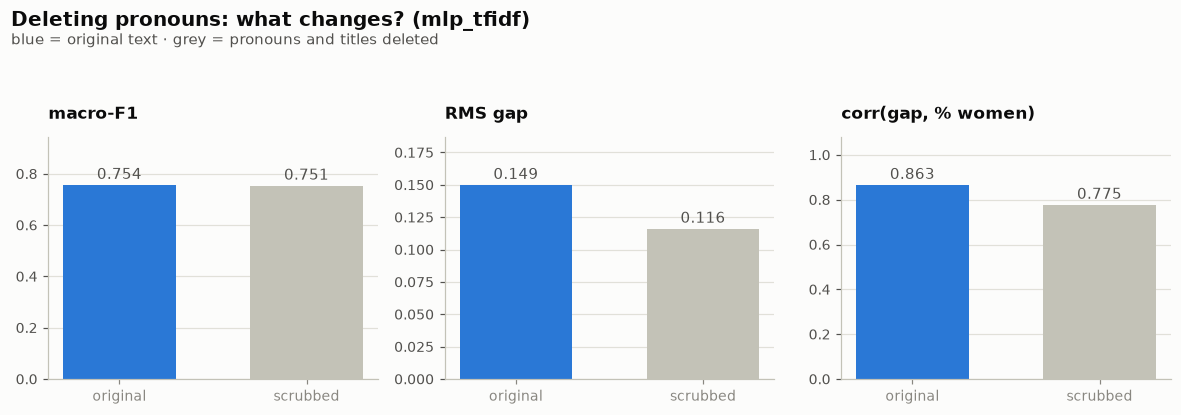

macro-F1 scrubbed − original: -0.0029 | P(original better) 0.00, P(practically equal) 1.00, P(scrubbed better) 0.00


,original,scrubbed
macro-F1,0.754,0.751
RMS gap,0.149,0.116
"corr(gap, % women)",0.863,0.775


In [55]:
# [11c] original vs scrubbed
scrub_scores = RES_SCRUB["scores"].sort_values(["seed", "fold"])["macro_f1"].to_numpy()
tables = [evaluation.tpr_by_gender(Y, RES_SCRUB["oof"][s], G, PROFESSIONS, MIN_GROUP) for s in SEEDS]
gaps_scrub = tables[0][["pct_female", "reported"]].join(sum(t[["gap"]] for t in tables) / len(tables))
compare = pd.DataFrame({
    "original": {"macro-F1": fold_scores_of(BEST).mean(), "RMS gap": fair.loc[BEST, "RMS gap"],
                 "corr(gap, % women)": fair.loc[BEST, "corr(gap, % women)"]},
    "scrubbed": {"macro-F1": scrub_scores.mean(), "RMS gap": evaluation.rms_gap(gaps_scrub),
                 "corr(gap, % women)": gaps_scrub.loc[gaps_scrub["reported"], "gap"].corr(gaps_scrub.loc[gaps_scrub["reported"], "pct_female"])},
})
fig = plots.before_after(compare, f"Deleting pronouns: what changes? ({BEST})", "blue = original text · grey = pronouns and titles deleted")
style.save(fig, FIGURES / "11_scrubbing.png"); plt.show()

post = analysis.BenavoliCorrelatedT(fold_scores_of(BEST), scrub_scores, runs=len(SEEDS), names=["original", "scrubbed"])
p_orig, p_eq, p_scrub = post.probs(ROPE)
print(f"macro-F1 scrubbed − original: {post.mean_diff:+.4f} | P(original better) {p_orig:.2f}, "
      f"P(practically equal) {p_eq:.2f}, P(scrubbed better) {p_scrub:.2f}")
compare.round(4)

> **This cell:** compare the gaps occupation by occupation, before and after scrubbing (largest original gaps first).

In [56]:
# [11d] per-occupation gaps before and after
per_occ = pd.DataFrame({"% women": GAPS[BEST]["pct_female"], "gap original": GAPS[BEST]["gap"], "gap scrubbed": gaps_scrub["gap"]})
per_occ["change"] = per_occ["gap scrubbed"].abs() - per_occ["gap original"].abs()
print(f"gap got smaller in {(per_occ['change'] < 0).sum()} of {K} occupations")
per_occ.reindex(per_occ["gap original"].abs().sort_values(ascending=False).index).head(10).round(3)

gap got smaller in 23 of 28 occupations


,% women,gap original,gap scrubbed,change
occupation,,,,
model,82.764,0.489,0.430,-0.059
dietitian,92.860,0.317,0.249,-0.068
paralegal,84.891,0.244,0.187,-0.057
rapper,9.660,-0.212,-0.134,-0.078
surgeon,14.835,-0.205,-0.128,-0.076
nurse,90.851,0.161,0.079,-0.082
pastor,24.022,-0.153,-0.087,-0.066
interior_designer,80.781,0.141,0.055,-0.086
teacher,60.251,0.130,0.113,-0.016


### 11.2 Does the log-linear model use *she* and *he* directly?

The log-linear model is a points table (5.1), so we can read its weights. For every occupation we look at
weight(*she*) − weight(*he*). If the model uses gender, this should be positive for female-dominated occupations and
negative for male-dominated ones.

> **This cell:** train one log-linear model on indicators (seed 0, fold 0 training part) and read off the weights of 'she' and 'he' for each occupation.

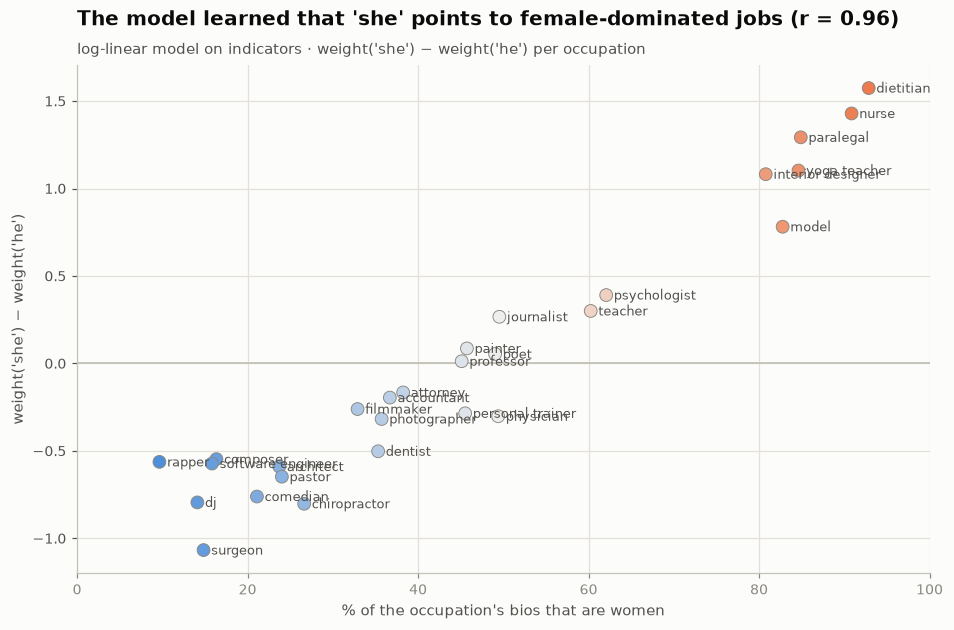

,#1,#2,#3,#4,#5,#6,#7,#8
nurse,nursing,nurse,nurses,rn,patients,hospital,np,midw
surgeon,surgery,surgeon,neuros,dr,surgeons,surgical,neurosurgery,medical
paralegal,paralegal,legal,law,attorneys,assists,litigation,preparation,firm
software_engineer,computer,software,google,developer,architecture,programming,code,yth
yoga_teacher,yoga,classes,yog,teaching,breath,students,practicing,india
professor,edu,ph,phd,psychologist,research,nurse,doctorate,academia


In [57]:
# [11e] pronoun weights of a log-linear model
X_ind = encoders.Indicator().transform(C[train0])
lin = models.Classifier("loglin", num_classes=K, **TUNED["loglin_indicator"]).fit(X_ind, Y[train0]).model
W = lin.coef_                                                   # 28 occupations x 10,000 tokens
she, he = tokenizer.token_to_id("▁she"), tokenizer.token_to_id("▁he")
pron = pd.DataFrame({"pct_female": GAPS[BEST]["pct_female"], "she_minus_he": W[:, she] - W[:, he]}, index=PROFESSIONS)
r = pron["she_minus_he"].corr(pron["pct_female"])
fig = plots.pronoun_weight_scatter(pron, f"The model learned that 'she' points to female-dominated jobs (r = {r:.2f})",
                                   "log-linear model on indicators · weight('she') − weight('he') per occupation")
style.save(fig, FIGURES / "11_pronoun_weights.png"); plt.show()

top = {PROFESSIONS[k]: [tokenizer.id_to_token(j).replace("▁", "") for j in np.argsort(-W[k])[:8]]
       for k in [PROFESSIONS.index(o) for o in ["nurse", "surgeon", "paralegal", "software_engineer", "yoga_teacher", "professor"]]}
pd.DataFrame(top).T.rename(columns=lambda c: f"#{c + 1}")

**What we see (11)**
- **Scrubbing works on the surface ([11a]):** no bio has a clear pronoun majority any more (94.9% → 0.0%).
- **Performance barely changes ([11c]):** macro-F1 0.754 → 0.751 (−0.003). Bayesian check: P(practically equal) = 1.00. The
  model hardly needed the pronouns to find the occupation.
- **Gaps shrink, but don't disappear:** RMS gap **0.149 → 0.116 (−22%)**, smaller in 23 of 28 occupations. The correlation with
  % women drops from 0.86 to **0.78**, so it's still strong. Biggest remaining gaps: model +0.43, dietitian +0.25, paralegal
  +0.19 ([11d]). Gender still leaks through **first names**, family words (*husband, mother*) and gender-typical topics.
  This is the same conclusion as De-Arteaga et al.
- **The log-linear model uses *she* and *he* systematically ([11e]):** weight(*she*) − weight(*he*) follows % women with
  **r = 0.96**. Dietitian, nurse and paralegal get the biggest push from *she* (+1.3 to +1.6); surgeon, DJ and chiropractor
  the biggest push from *he* (−0.8 to −1.1). But the *top* words per occupation are content words (*nursing, patients* for
  nurse; *surgery, surgical* for surgeon; *legal, litigation* for paralegal). Pronouns are a secondary but steady nudge,
  exactly what tips ambiguous bios towards the gender-typical job.

**So what.** Removing explicit gender words is cheap (no accuracy loss) and reduces unfairness by about a fifth, but it is
not a fix. That's a good starting point for Projects 2–3 (e.g. removing names, or debiasing the representation).

## 12 · Summary for the 5 backup slides

| slide | key points | figure(s) in `figures/week1/` |
|---|---|---|
| **1 · Data & metrics** | 257k bios, 28 occupations, professor 30%, 84× imbalance; % women 10–93% per job; pronouns reveal gender in 95% of bios. "Always professor" = 0.30 accuracy but 0.016 macro-F1 → **macro-F1** as main score; fairness = TPR gap (women − men recall) and its RMS | `1_4_occupation_distribution`, `1_4_baselines`, `1_5_gender_by_occupation`, `1_7_pronoun_gender` |
| **2 · Features** | own BPE tokenizer (10k, lowercase, punctuation split, 21/28 job names = 1 token); R1 indicator, R2 counts, **R3 TF-IDF** (damp repeats, down-weight common words incl. pronouns, remove length; idf learned on training folds only); 78% of counts are 1 → R1 ≈ R2 | `3_tokens_example`, `diagrams/representations`, `4_count_distribution`, `4_idf_pronouns` |
| **3 · Architectures** | log-linear (280k weights, convex, additive clues), MLP 1×128 (1.3M, combinations), **deeper MLP** 256→128 (2.6M); AdamW, early stopping on an inner 10% hold-out (not the validation fold); one setting tuned per system (C 0.3 / 3 for TF-IDF; lr 0.001) | `diagrams/architectures`, `5_training_curves`, `5_tuning` |
| **4 · Results** | 3 folds × 2 seeds, stratified. Best **mlp_tfidf 0.754 ± 0.002**. One hidden layer helps (+0.02–0.03) unless TF-IDF is used (then log-linear ≈ MLP); a 2nd layer doesn't help; indicator ≈ counts. ROPE ±0.01 (4× fold noise), conclusions hold for ROPE 0.005–0.02 | `8_grid_heatmap`, `8_fold_scores`, `9_comparisons`, `9_posterior_*` |
| **5 · Extra: fairness** | gap vs % women r = 0.86 (all systems 0.82–0.90): model +0.49, surgeon −0.21. Minority gender pushed to the related job (male paralegal → attorney, female surgeon → physician). Scrubbing pronouns: macro-F1 −0.003 (equal), RMS gap −22% but correlation still 0.78; log-linear she−he weights r = 0.96 | `10_gap_vs_female`, `10_rms_gap`, `11_scrubbing`, `11_pronoun_weights`, `8_confusion` |

**Limitations to mention if asked:** gender is binary and inferred; only 6 CV scores (wider posteriors); one hyperparameter
tuned per system, on one fold; `loglin_bow` didn't fully converge; near-duplicate templates can sit in both training and
validation parts; scrubbing leaves names; dev/test not used yet.

## 13 · Sources and AI assistance

**Sources.** De-Arteaga et al. (2019), *Bias in Bios* (dataset, scrubbing, gap vs % women) · Ravfogel et al. (2020)
(this Hugging Face version) · Romanov et al. (2019) (RMS gap) · Hardt et al. (2016) (equality of opportunity) ·
Sennrich et al. (2016) (BPE) · Benavoli et al. (2017), Corani & Benavoli (2015), Nadeau & Bengio (2003) (Bayesian
correlated t-test and its correction) · the NLP1 tutorial notebook and its `part1` code.

**AI assistance.** We used Claude Code (an AI coding assistant) for code, figures and drafts of the explanations.
Every task, and what we checked or changed, is logged in `docs/ai_assistance_log.md`. All numbers in the text come
from the outputs of this notebook.